<a href="https://colab.research.google.com/github/Rashi158/datasciproj/blob/main/01_setupanddata.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi

Sat Oct 31 02:59:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT = '/content/drive/MyDrive/pa_en_tokenization'
for d in ['data/raw', 'data/clean', 'data/splits', 'tokenizers', 'models', 'results']:
    os.makedirs(f'{PROJECT}/{d}', exist_ok=True)
print(os.listdir(PROJECT))

Mounted at /content/drive
['data', 'tokenizers', 'models', 'results']


In [ ]:
!pip install -q sentencepiece morfessor sacrebleu datasets networkx

In [ ]:
import sentencepiece, morfessor, sacrebleu, datasets, networkx, torch
print("Sab ready hai!")
print("GPU:", torch.cuda.is_available())

Sab ready hai!
GPU: True


In [ ]:
from datasets import load_dataset
import pandas as pd

sam = load_dataset("ai4bharat/samanantar", "pa", split="train")
print(sam.column_names)

df = sam.shuffle(seed=42).select(range(300000)).to_pandas()
df = df.rename(columns={"src": "en", "tgt": "pa"})[["en", "pa"]]
df.to_parquet(f"{PROJECT}/data/raw/samanantar_pa_300k.parquet", index=False)
print(df.shape)

README.md:   0%|          | 0.00/11.4k [00:00<?, ?B/s]

pa/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  235MB            

pa/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

pa/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  235MB            

pa/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2980383 [00:00<?, ? examples/s]

['idx', 'src', 'tgt']
(300000, 2)


In [ ]:
!wget -q https://dl.fbaipublicfiles.com/nllb/flores200_dataset.tar.gz -O /content/flores200.tar.gz
!tar -xzf /content/flores200.tar.gz -C /content/
!ls /content/flores200_dataset

dev  devtest  metadata_devtest.tsv  metadata_dev.tsv  README


In [ ]:
def read_lines(path):
    with open(path, encoding="utf-8") as f:
        return [line.rstrip("\n") for line in f]

base = "/content/flores200_dataset"
flores = {}
for split in ["dev", "devtest"]:
    en = read_lines(f"{base}/{split}/eng_Latn.{split}")
    pa = read_lines(f"{base}/{split}/pan_Guru.{split}")
    flores[split] = pd.DataFrame({"id": range(len(en)), "en": en, "pa": pa})
    flores[split].to_parquet(f"{PROJECT}/data/raw/flores_{split}.parquet", index=False)
    print(split, flores[split].shape)

dev (997, 3)
devtest (1012, 3)


In [ ]:
for i in range(5):
    print("EN:", df.en[i])
    print("PA:", df.pa[i])
    print("-" * 60)

EN: Residents protest outside DEO office against shortage of teachers
PA: ਗੌਰਮਿੰਟ ਟੀਚਰਜ਼ ਯੂਨੀਅਨ ਵੱਲੋਂ ਡੀਈਓ ਦਫ਼ਤਰ ਦਾ ਘਿਰਾਓ
------------------------------------------------------------
EN: The way he played was fantastic.
PA: ਉਹ ਜਿਸ ਤਰ੍ਹਾ ਨਾਲ ਖੇਡੇ ਉਹ ਸ਼ਾਨਦਾਰ ਸੀ।
------------------------------------------------------------
EN: He recalls: Once we were asked to bring in a favorite baby picture for a school project.
PA: ਉਹ ਚੇਤੇ ਕਰਦਾ ਹੈ: “ਇਕ ਵਾਰ ਸਾਨੂੰ ਇਕ ਸਕੂਲ ਪ੍ਰਾਜੈਕਟ ਲਈ ਬਚਪਨ ਦੀ ਇਕ ਮਨਭਾਉਂਦੀ ਤਸਵੀਰ ਲਿਆਉਣ ਲਈ ਕਿਹਾ ਗਿਆ ।
------------------------------------------------------------
EN: The institute is also contributing to the Swasthya Rakshan Program at five adopted villages i.e.
PA: ਇਹ ਸੰਸਥਾ ਪੰਜ ਗੋਦ ਲਏ ਪਿੰਡਾਂ, ਪਿੰਡਾਂ ਵਿਖੇ ਸਵਸਥਯ ਰਕਸ਼ਣ ਪ੍ਰੋਗਰਾਮ ਵਿੱਚ ਵੀ ਯੋਗਦਾਨ ਪਾ ਰਹੀ ਹੈ।
------------------------------------------------------------
EN: Dressing tips
PA: ਪਹਿਨਣ ਵਾਲੇ ਸੁਝਾਅ
------------------------------------------------------------


In [ ]:
import unicodedata, re

def norm(s):
    s = unicodedata.normalize("NFC", str(s))
    return re.sub(r"\s+", " ", s).strip()

def gurmukhi_ratio(s):
    letters = [c for c in s if c.isalpha()]
    if not letters: return 0
    return sum('\u0A00' <= c <= '\u0A7F' for c in letters) / len(letters)

def latin_ratio(s):
    letters = [c for c in s if c.isalpha()]
    if not letters: return 0
    return sum(c.isascii() for c in letters) / len(letters)

log = []
def step(name, d):
    log.append((name, len(d)))
    print(f"{name:30s} {len(d):>8,}")
    return d

data = step("Start", df.copy())

data["en"] = data["en"].map(norm)
data["pa"] = data["pa"].map(norm)
data = step("Empty hataye", data[(data.en != "") & (data.pa != "")])

data = step("Duplicate pairs hataye", data.drop_duplicates(subset=["en", "pa"]))
data = step("Duplicate English hataye", data.drop_duplicates(subset=["en"]))
data = step("Duplicate Punjabi hataye", data.drop_duplicates(subset=["pa"]))

data["en_len"] = data.en.str.split().str.len()
data["pa_len"] = data.pa.str.split().str.len()
data = step("Length 3 se 80 words", data[data.en_len.between(3, 80) & data.pa_len.between(3, 80)])

ratio = data.pa_len / data.en_len
data = step("Length ratio 0.6 se 2.0", data[ratio.between(0.6, 2.0)])

data = step("Script check", data[(data.pa.map(gurmukhi_ratio) >= 0.8) & (data.en.map(latin_ratio) >= 0.9)])

for split in flores:
    flores[split]["en"] = flores[split]["en"].map(norm)
    flores[split]["pa"] = flores[split]["pa"].map(norm)
test_en = set(flores["dev"].en) | set(flores["devtest"].en)
test_pa = set(flores["dev"].pa) | set(flores["devtest"].pa)
data = step("FLORES overlap hataya", data[~data.en.isin(test_en) & ~data.pa.isin(test_pa)])

data = data.reset_index(drop=True)

Start                           300,000
Empty hataye                    300,000
Duplicate pairs hataye          299,896
Duplicate English hataye        274,947
Duplicate Punjabi hataye        273,893
Length 3 se 80 words            261,768
Length ratio 0.6 se 2.0         247,066
Script check                    244,910
FLORES overlap hataya           244,910


In [ ]:
assert len(data) >= 50000, "Clean data 50k se kam hai, mujhe batana"

for n in [10000, 25000, 50000]:
    part = data.iloc[:n][["en", "pa"]]
    part.to_parquet(f"{PROJECT}/data/splits/train_{n//1000}k.parquet", index=False)
    print(f"train_{n//1000}k:", part.shape)

flores["dev"][["en", "pa"]].to_parquet(f"{PROJECT}/data/splits/valid.parquet", index=False)
flores["devtest"][["en", "pa"]].to_parquet(f"{PROJECT}/data/splits/test.parquet", index=False)
data[["en", "pa"]].to_parquet(f"{PROJECT}/data/clean/samanantar_clean.parquet", index=False)

log_df = pd.DataFrame(log, columns=["Step", "Pairs left"])
log_df.to_csv(f"{PROJECT}/results/cleaning_log.csv", index=False)
log_df

train_10k: (10000, 2)
train_25k: (25000, 2)
train_50k: (50000, 2)


,Step,Pairs left
0,Start,300000
1,Empty hataye,300000
2,Duplicate pairs hataye,299896
3,Duplicate English hataye,274947
4,Duplicate Punjabi hataye,273893
5,Length 3 se 80 words,261768
6,Length ratio 0.6 se 2.0,247066
7,Script check,244910
8,FLORES overlap hataya,244910


In [ ]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

FIG = f"{PROJECT}/results/figures"
os.makedirs(FIG, exist_ok=True)

train = {k: pd.read_parquet(f"{PROJECT}/data/splits/train_{k}.parquet") for k in ["10k", "25k", "50k"]}
valid = pd.read_parquet(f"{PROJECT}/data/splits/valid.parquet")
test = pd.read_parquet(f"{PROJECT}/data/splits/test.parquet")
tr = train["50k"]

PUNCT = "!\"#$%&'()*+,-./:;<=>?@[\\]^_`{|}~।॥“”‘’…"

def tokenize(s, lang):
    toks = [w.strip(PUNCT) for w in s.split()]
    toks = [w for w in toks if w]
    return [w.lower() for w in toks] if lang == "en" else toks

for k, v in train.items():
    print(f"train_{k}:", v.shape)
print("valid:", valid.shape, " test:", test.shape)

train_10k: (10000, 2)
train_25k: (25000, 2)
train_50k: (50000, 2)
valid: (997, 2)  test: (1012, 2)


In [ ]:
demo = "ਮੁੰਡਾ ਕਿਤਾਬ ਪੜ੍ਹਦਾ ਹੈ।"
print("Asli sentence:      ", demo)
print("Whitespace split:   ", demo.split())
print("Regex \\w+ split:    ", re.findall(r"\w+", demo))

Asli sentence:       ਮੁੰਡਾ ਕਿਤਾਬ ਪੜ੍ਹਦਾ ਹੈ।
Whitespace split:    ['ਮੁੰਡਾ', 'ਕਿਤਾਬ', 'ਪੜ੍ਹਦਾ', 'ਹੈ।']
Regex \w+ split:     ['ਮ', 'ਡ', 'ਕ', 'ਤ', 'ਬ', 'ਪੜ', 'ਹਦ', 'ਹ']


In [ ]:
rows = []
for lang, name in [("en", "English"), ("pa", "Punjabi")]:
    toks_per_sent = tr[lang].map(lambda s: tokenize(s, lang))
    lens = toks_per_sent.str.len()
    freq = Counter(w for t in toks_per_sent for w in t)
    total = int(lens.sum())
    rows.append({
        "Language": name,
        "Sentences": len(tr),
        "Total words": total,
        "Unique words (vocabulary)": len(freq),
        "Avg words per sentence": round(lens.mean(), 1),
        "Median words per sentence": int(lens.median()),
        "Type-token ratio": round(len(freq) / total, 4),
        "Words seen only once (%)": round(100 * sum(c == 1 for c in freq.values()) / len(freq), 1),
    })
stats = pd.DataFrame(rows).set_index("Language").astype(object).T
stats.to_csv(f"{PROJECT}/results/eda_basic_stats.csv")
stats

Language,English,Punjabi
Sentences,50000,50000
Total words,695846,769914
Unique words (vocabulary),40169,45183
Avg words per sentence,13.9,15.4
Median words per sentence,11,12
Type-token ratio,0.0577,0.0587
Words seen only once (%),50.0,54.8


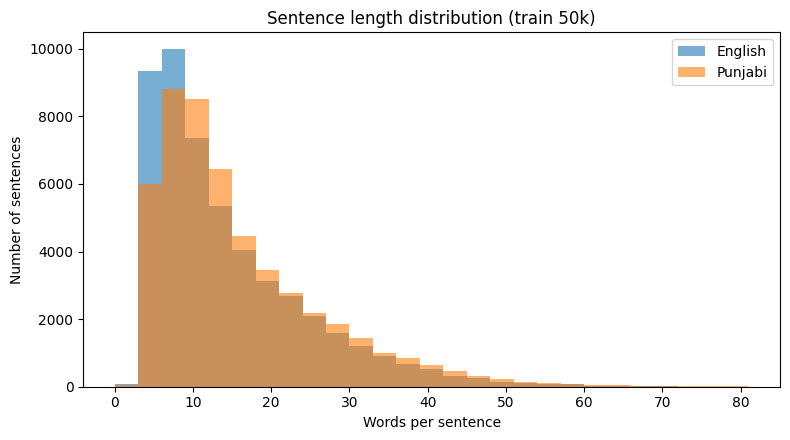

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.arange(0, 84, 3)
for lang, name in [("en", "English"), ("pa", "Punjabi")]:
    ax.hist(tr[lang].map(lambda s: len(tokenize(s, lang))), bins=bins, alpha=0.6, label=name)
ax.set_xlabel("Words per sentence")
ax.set_ylabel("Number of sentences")
ax.set_title("Sentence length distribution (train 50k)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG}/01_sentence_length.png", dpi=200)
plt.show()

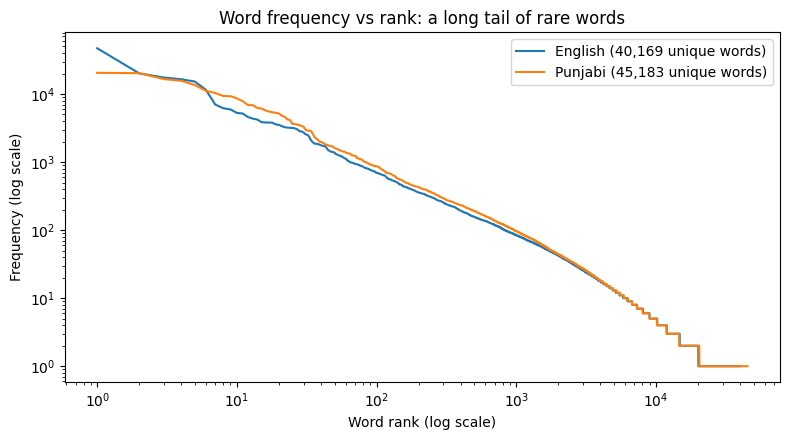

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for lang, name in [("en", "English"), ("pa", "Punjabi")]:
    freq = Counter(w for s in tr[lang] for w in tokenize(s, lang))
    counts = np.array(sorted(freq.values(), reverse=True))
    ax.loglog(np.arange(1, len(counts) + 1), counts, label=f"{name} ({len(counts):,} unique words)")
ax.set_xlabel("Word rank (log scale)")
ax.set_ylabel("Frequency (log scale)")
ax.set_title("Word frequency vs rank: a long tail of rare words")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG}/02_zipf.png", dpi=200)
plt.show()

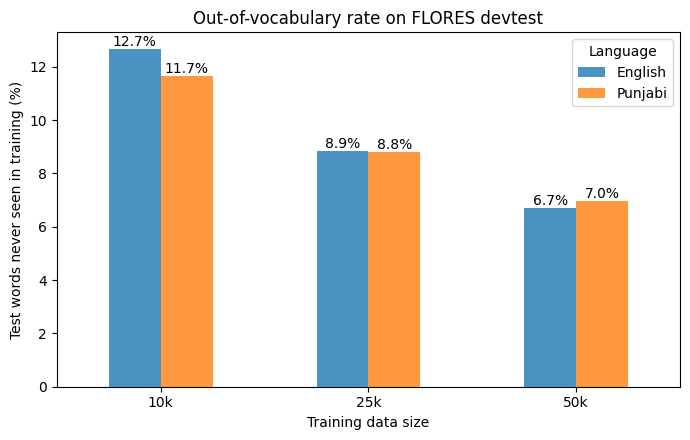

Language,English,Punjabi
Train size,,
10k,12.66,11.66
25k,8.86,8.82
50k,6.70,6.98


In [ ]:
test_tokens = {lang: [w for s in test[lang] for w in tokenize(s, lang)] for lang in ["en", "pa"]}
oov_rows = []
for k, d in train.items():
    for lang, name in [("en", "English"), ("pa", "Punjabi")]:
        vocab = set(w for s in d[lang] for w in tokenize(s, lang))
        toks = test_tokens[lang]
        oov_rows.append({"Train size": k, "Language": name,
                         "OOV %": round(100 * sum(w not in vocab for w in toks) / len(toks), 2)})
oov_df = pd.DataFrame(oov_rows)
oov_df.to_csv(f"{PROJECT}/results/eda_oov.csv", index=False)

pivot = oov_df.pivot(index="Train size", columns="Language", values="OOV %").loc[["10k", "25k", "50k"]]
ax = pivot.plot(kind="bar", figsize=(7, 4.5), rot=0, alpha=0.8)
ax.set_xlabel("Training data size")
ax.set_ylabel("Test words never seen in training (%)")
ax.set_title("Out-of-vocabulary rate on FLORES devtest")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%")
plt.tight_layout()
plt.savefig(f"{FIG}/03_oov_rate.png", dpi=200)
plt.show()
pivot

In [ ]:
pa_freq = Counter(w for s in tr["pa"] for w in tokenize(s, "pa"))
BAD_END = {"\u0A4D", "\u0A3C", "\u0A71"}   # virama, nukta, addak: stem yahan khatam nahi ho sakta
BAD_START = {"\u0A4D", "\u0A3C"}           # suffix virama ya nukta se shuru nahi ho sakta

stem_forms = {}
for w in pa_freq:
    for k in range(1, 4):
        stem, suf = w[:-k], w[-k:]
        if len(stem) < 2 or stem[-1] in BAD_END or suf[0] in BAD_START:
            continue
        stem_forms.setdefault(stem, {})[suf] = w

families = {st: f for st, f in stem_forms.items() if len(f) >= 2}
suffix_degree = Counter(suf for f in families.values() for suf in f)

suf_rows = []
for suf, deg in suffix_degree.most_common(15):
    examples = sorted((f[suf] for f in families.values() if suf in f), key=lambda w: -pa_freq[w])[:3]
    suf_rows.append({"Suffix": "-" + suf, "Stems it attaches to": deg, "Example words": ", ".join(examples)})
top_suf = pd.DataFrame(suf_rows)
top_suf.to_csv(f"{PROJECT}/results/eda_top_suffixes.csv", index=False)
top_suf.style.bar(subset=["Stems it attaches to"], color="#7fb3d5").hide(axis="index")

Suffix,Stems it attaches to,Example words
-ੀ,2186,"ਕੀਤੀ, ਮੰਤਰੀ, ਦਿੱਤੀ"
-ਾ,1980,"ਕੀਤਾ, ਕਿਹਾ, ਦਿੱਤਾ"
-ੇ,1559,"ਅਤੇ, ਆਪਣੇ, ਰਹੇ"
-ਰ,1089,"ਸਰਕਾਰ, ਹੋਰ, ਕੁਮਾਰ"
-ਾਂ,1018,"ਉਨ੍ਹਾਂ, ਲੋਕਾਂ, ਇਨ੍ਹਾਂ"
-ਨ,984,"ਕਰਨ, ਪ੍ਰਧਾਨ, ਦੌਰਾਨ"
-ੀਆਂ,882,"ਵਿਦਿਆਰਥੀਆਂ, ਅਧਿਕਾਰੀਆਂ, ਕੀਤੀਆਂ"
-ਲ,644,"ਨਾਲ, ਸ਼ਾਮਲ, ਹਸਪਤਾਲ"
-ਸ,553,"ਜਿਸ, ਕਾਂਗਰਸ, ਕੇਸ"
-ਣ,537,"ਜਾਣ, ਦੇਣ, ਹੋਣ"


In [ ]:
cands = []
for st, f in families.items():
    if len(f) >= 4:
        forms = sorted(f.values(), key=lambda w: -pa_freq[w])
        cands.append((sum(pa_freq[w] for w in forms), len(st), st, forms))
cands.sort(reverse=True)

fam_rows, used = [], []
for total, _, st, forms in cands:
    if any(len(set(forms) & u) >= 0.5 * len(forms) for u in used):
        continue
    used.append(set(forms))
    fam_rows.append({"Stem": st, "Forms found": len(forms), "Total frequency": total, "Forms": ", ".join(forms[:6])})
    if len(fam_rows) == 12:
        break
top_fam = pd.DataFrame(fam_rows)
top_fam.to_csv(f"{PROJECT}/results/eda_word_families.csv", index=False)
top_fam

,Stem,Forms found,Total frequency,Forms
0,ਵਿ,183,18730,"ਵਿੱਚ, ਵਿਚ, ਵਿਕਾਸ, ਵਿਭਾਗ, ਵਿਖੇ, ਵਿਸ਼ਵ"
1,ਨੂ,12,15672,"ਨੂੰ, ਨੂਹ, ਨੂੰਹ, ਨੂੰੂ, ਨੂਰ, ਨੂਰੀ"
2,ਅਤ,15,11201,"ਅਤੇ, ਅਤਿ, ਅਤੁਲ, ਅਤੁੱਟ, ਅਤੀਤ, ਅਤਬਾਰ"
3,ਕਰ,141,10310,"ਕਰਨ, ਕਰਕੇ, ਕਰਦੇ, ਕਰਨਾ, ਕਰਦਾ, ਕਰੋ"
4,ਕੀਤ,8,8900,"ਕੀਤਾ, ਕੀਤੀ, ਕੀਤੇ, ਕੀਤੀਆਂ, ਕੀਤੈ, ਕੀਤੂ"
5,ਕੀ,30,8881,"ਕੀਤਾ, ਕੀਤੀ, ਕੀਤੇ, ਕੀਮਤ, ਕੀਰਤਨ, ਕੀਮਤੀ"
6,ਸਿ,142,7863,"ਸਿੰਘ, ਸਿਹਤ, ਸਿੱਖ, ਸਿਰਫ਼, ਸਿਵਲ, ਸਿਰਫ"
7,ਨਾ,125,7584,"ਨਾਲ, ਨਾਂ, ਨਾਨਕ, ਨਾਮ, ਨਾਲੋਂ, ਨਾਕਾਮ"
8,ਦਿ,87,7134,"ਦਿੱਤਾ, ਦਿੱਤੀ, ਦਿੱਲੀ, ਦਿਨ, ਦਿੱਤੇ, ਦਿਨਾਂ"
9,ਤੋ,44,7063,"ਤੋਂ, ਤੋੜ, ਤੋਮਰ, ਤੋੜਨ, ਤੋਬਾ, ਤੋੜਿਆ"


In [ ]:
rows = []
for k, d in train.items():
    for lang, name in [("en", "English"), ("pa", "Punjabi")]:
        freq = Counter(w for s in d[lang] for w in tokenize(s, lang))
        common = set(w for w, _ in freq.most_common(100))
        toks = [w for w in test_tokens[lang] if w not in common]
        rows.append({"Train size": k, "Language": name,
                     "Content-word OOV %": round(100 * sum(w not in freq for w in toks) / max(len(toks), 1), 2)})
oov2 = pd.DataFrame(rows).pivot(index="Train size", columns="Language", values="Content-word OOV %").loc[["10k", "25k", "50k"]]
oov2.to_csv(f"{PROJECT}/results/eda_oov_content_words.csv")
oov2

Language,English,Punjabi
Train size,,
10k,21.57,19.80
25k,15.14,15.01
50k,11.44,11.94


In [ ]:
import os, time
import pandas as pd
import sentencepiece as spm
import morfessor
from collections import Counter

SIZES = ["10k", "25k", "50k"]
VOCAB = 8000                       # har tokenizer max 8000 pieces seekhega (sab ke liye same)
TOK = f"{PROJECT}/tokenizers"
PRETOK = f"{PROJECT}/data/pretok"
TMP = "/content/tok_tmp"
for d in [TOK, PRETOK, TMP]:
    os.makedirs(d, exist_ok=True)

train = {k: pd.read_parquet(f"{PROJECT}/data/splits/train_{k}.parquet") for k in SIZES}
valid = pd.read_parquet(f"{PROJECT}/data/splits/valid.parquet")
test = pd.read_parquet(f"{PROJECT}/data/splits/test.parquet")

def train_sp(lines, name, model_type, coverage=1.0, **extra):
    # SentencePiece tokenizer train karke Drive par save karta hai
    txt = f"{TMP}/{name}.txt"
    with open(txt, "w", encoding="utf-8") as f:
        f.write("\n".join(lines) + "\n")
    spm.SentencePieceTrainer.train(
        input=txt, model_prefix=f"{TOK}/{name}", vocab_size=VOCAB,
        model_type=model_type, character_coverage=coverage,
        pad_id=0, unk_id=1, bos_id=2, eos_id=3,
        input_sentence_size=1000000, shuffle_input_sentence=True,
        minloglevel=2, **extra,
    )
    return spm.SentencePieceProcessor(model_file=f"{TOK}/{name}.model")

print("Train:", {k: len(v) for k, v in train.items()}, "Valid:", len(valid), "Test:", len(test))

Train: {'10k': 10000, '25k': 25000, '50k': 50000} Valid: 997 Test: 1012


In [ ]:
# English side ka tokenizer har method ke liye same rahega,
# kyunki project sirf Punjabi side ki tokenization badalta hai
t0 = time.time()
for k in SIZES:
    train_sp(train[k]["en"].tolist(), f"en_bpe_{k}", "bpe", coverage=0.9999)
    print(f"en_bpe_{k} ready")
print(f"{time.time()-t0:.0f} sec")

en_bpe_10k ready
en_bpe_25k ready
en_bpe_50k ready
4 sec


In [ ]:
# BPE: sabse zyada saath aane wale do pieces ko baar baar jodta hai (bottom-up)
# Unigram: bade vocabulary se shuru karke kam kaam ke pieces hatata hai (top-down)
t0 = time.time()
sp = {}
for k in SIZES:
    for method in ["bpe", "unigram"]:
        sp[(method, k)] = train_sp(train[k]["pa"].tolist(), f"pa_{method}_{k}", method)
        print(f"pa_{method}_{k} ready")
print(f"{time.time()-t0:.0f} sec")

pa_bpe_10k ready
pa_unigram_10k ready
pa_bpe_25k ready
pa_unigram_25k ready
pa_bpe_50k ready
pa_unigram_50k ready
21 sec


In [ ]:
pd.set_option("display.max_colwidth", None)
examples = [
    "ਉਹ ਸਕੂਲ ਵਿੱਚ ਪੜ੍ਹਦੀ ਹੈ।",                 # She studies in school.
    "ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾਬਾਂ ਲਿਖੀਆਂ।",     # The students wrote their books.
]
rows = []
for s in examples:
    for k in SIZES:
        for method in ["bpe", "unigram"]:
            toks = sp[(method, k)].encode(s, out_type=str)
            rows.append({"Sentence": s[:25], "Train size": k, "Method": method,
                         "Count": len(toks), "Pieces": " | ".join(toks)})
pd.DataFrame(rows)

,Sentence,Train size,Method,Count,Pieces
0,ਉਹ ਸਕੂਲ ਵਿੱਚ ਪੜ੍ਹਦੀ ਹੈ।,10k,bpe,7,▁ਉਹ | ▁ਸਕੂਲ | ▁ਵਿੱਚ | ▁ਪੜ੍ਹ | ਦੀ | ▁ਹੈ | ।
1,ਉਹ ਸਕੂਲ ਵਿੱਚ ਪੜ੍ਹਦੀ ਹੈ।,10k,unigram,7,▁ਉਹ | ▁ਸਕੂਲ | ▁ਵਿੱਚ | ▁ਪੜ੍ਹ | ਦੀ | ▁ਹੈ | ।
2,ਉਹ ਸਕੂਲ ਵਿੱਚ ਪੜ੍ਹਦੀ ਹੈ।,25k,bpe,7,▁ਉਹ | ▁ਸਕੂਲ | ▁ਵਿੱਚ | ▁ਪੜ੍ਹ | ਦੀ | ▁ਹੈ | ।
3,ਉਹ ਸਕੂਲ ਵਿੱਚ ਪੜ੍ਹਦੀ ਹੈ।,25k,unigram,7,▁ਉਹ | ▁ਸਕੂਲ | ▁ਵਿੱਚ | ▁ਪੜ੍ਹ | ਦੀ | ▁ਹੈ | ।
4,ਉਹ ਸਕੂਲ ਵਿੱਚ ਪੜ੍ਹਦੀ ਹੈ।,50k,bpe,7,▁ਉਹ | ▁ਸਕੂਲ | ▁ਵਿੱਚ | ▁ਪੜ੍ਹ | ਦੀ | ▁ਹੈ | ।
5,ਉਹ ਸਕੂਲ ਵਿੱਚ ਪੜ੍ਹਦੀ ਹੈ।,50k,unigram,7,▁ਉਹ | ▁ਸਕੂਲ | ▁ਵਿੱਚ | ▁ਪੜ੍ਹ | ਦੀ | ▁ਹੈ | ।
6,ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾ,10k,bpe,7,▁ਵਿਦਿਆਰਥੀਆਂ | ▁ਨੇ | ▁ਆਪਣੀਆਂ | ▁ਕਿਤਾਬਾਂ | ▁ਲਿਖ | ੀਆਂ | ।
7,ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾ,10k,unigram,7,▁ਵਿਦਿਆਰਥੀਆਂ | ▁ਨੇ | ▁ਆਪਣੀਆਂ | ▁ਕਿਤਾਬਾਂ | ▁ਲਿਖ | ੀਆਂ | ।
8,ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾ,25k,bpe,7,▁ਵਿਦਿਆਰਥੀਆਂ | ▁ਨੇ | ▁ਆਪਣੀਆਂ | ▁ਕਿਤਾਬਾਂ | ▁ਲਿਖ | ੀਆਂ | ।
9,ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾ,25k,unigram,7,▁ਵਿਦਿਆਰਥੀਆਂ | ▁ਨੇ | ▁ਆਪਣੀਆਂ | ▁ਕਿਤਾਬਾਂ | ▁ਲਿਖ | ੀਆਂ | ।


In [ ]:
# Idea: BPE chalne se PEHLE word ke andar ek "deewar" lagao, jaise ਕਰਦਾ -> ਕਰ␟ਦਾ
# SentencePiece ka option pretokenization_delimiter BPE ko is deewar ke paar jodne nahi deta.
# Encoding ke baad deewar wala symbol hata dete hain, toh koi extra token nahi banta.
PUNCT = "!\"#$%&'()*+,-./:;<=>?@[\\]^_`{|}~।॥“”‘’…"
BAD_END = {"\u0A4D", "\u0A71"}     # virama, addak: piece inke baad khatam nahi ho sakta
BAD_START = {"\u0A4D", "\u0A3C"}   # virama, nukta: piece inse shuru nahi ho sakta
DELIM = "\u241F"                   # deewar ka symbol

def is_gurmukhi(w):
    return len(w) > 0 and all("\u0A00" <= c <= "\u0A7F" for c in w)

def split_punct(tok):
    # "ਹੈ।" -> ("", "ਹੈ", "।")
    core = tok.strip(PUNCT)
    if not core:
        return tok, "", ""
    i = tok.index(core)
    return tok[:i], core, tok[i + len(core):]

def fix_pieces(pieces):
    # Gurmukhi ke niyam todne wale cuts ko wapas jodta hai
    out = []
    for p in pieces:
        if out and (out[-1][-1] in BAD_END or p[0] in BAD_START):
            out[-1] += p
        else:
            out.append(p)
    return out

def pretokenize(sentence, segment):
    # Har Gurmukhi word ke andar deewar lagata hai
    out = []
    for tok in sentence.split():
        lead, core, trail = split_punct(tok)
        if is_gurmukhi(core) and len(core) >= 3:
            pieces = fix_pieces(segment(core))
        else:
            pieces = [core] if core else []
        out.append(lead + DELIM.join(pieces) + trail if pieces else tok)
    return " ".join(out)

def gurmukhi_word_counts(sentences):
    c = Counter()
    for s in sentences:
        for tok in s.split():
            core = split_punct(tok)[1]
            if is_gurmukhi(core):
                c[core] += 1
    return c

# Test: har word ke aakhri 2 letter alag karke dekho
print(pretokenize("ਉਹ ਕਿਤਾਬ ਪੜ੍ਹਦਾ ਹੈ।", lambda w: [w[:-2], w[-2:]]))

ਉਹ ਕਿਤ␟ਾਬ ਪੜ੍ਹ␟ਦਾ ਹੈ।


In [ ]:
# Morfessor bina labels ke words ko stem + suffix mein todna seekhta hai (unsupervised).
# Naye word ke liye Viterbi algorithm best split dhundhta hai.
morf = {}
for k in SIZES:
    t0 = time.time()
    counts = gurmukhi_word_counts(train[k]["pa"])
    model = morfessor.BaselineModel()
    model.load_data([(1, w) for w in counts])      # har unique word ek baar
    model.train_batch()
    morfessor.MorfessorIO().write_binary_model_file(f"{TOK}/morfessor_{k}.bin", model)

    cache = {}
    def segment(w, model=model, cache=cache):
        if w not in cache:
            cache[w] = model.viterbi_segment(w)[0]
        return cache[w]
    morf[k] = segment

    for name, d in [(f"train_{k}", train[k]), ("valid", valid), ("test", test)]:
        out = d.copy()
        out["pa"] = out["pa"].map(lambda s: pretokenize(s, segment))
        out.to_parquet(f"{PRETOK}/morfessor_{k}_{name}.parquet", index=False)

    pre_train = pd.read_parquet(f"{PRETOK}/morfessor_{k}_train_{k}.parquet")
    sp[("morfessor", k)] = train_sp(pre_train["pa"].tolist(), f"pa_morfessor_{k}", "bpe",
                                    pretokenization_delimiter=DELIM, user_defined_symbols=[DELIM])
    print(f"\nmorfessor_{k}: {len(counts):,} word types, {time.time()-t0:.0f} sec")

100% (16660 of 16660) |##################| Elapsed Time: 0:00:02 Time:  0:00:02
100% (16660 of 16660) |##################| Elapsed Time: 0:00:03 Time:  0:00:03
100% (16660 of 16660) |##################| Elapsed Time: 0:00:03 Time:  0:00:03
100% (16660 of 16660) |##################| Elapsed Time: 0:00:03 Time:  0:00:03
100% (16660 of 16660) |##################| Elapsed Time: 0:00:03 Time:  0:00:03
100% (16660 of 16660) |##################| Elapsed Time: 0:00:03 Time:  0:00:03
100% (16660 of 16660) |##################| Elapsed Time: 0:00:03 Time:  0:00:03
100% (16660 of 16660) |##################| Elapsed Time: 0:00:03 Time:  0:00:03
100% (16660 of 16660) |##################| Elapsed Time: 0:00:03 Time:  0:00:03
100% (16660 of 16660) |##################| Elapsed Time: 0:00:03 Time:  0:00:03
100% (16660 of 16660) |##################| Elapsed Time: 0:00:03 Time:  0:00:03



morfessor_10k: 16,660 word types, 41 sec


100% (27430 of 27430) |##################| Elapsed Time: 0:00:04 Time:  0:00:04
100% (27430 of 27430) |##################| Elapsed Time: 0:00:05 Time:  0:00:05
100% (27430 of 27430) |##################| Elapsed Time: 0:00:05 Time:  0:00:05
100% (27430 of 27430) |##################| Elapsed Time: 0:00:05 Time:  0:00:05
100% (27430 of 27430) |##################| Elapsed Time: 0:00:05 Time:  0:00:05
100% (27430 of 27430) |##################| Elapsed Time: 0:00:05 Time:  0:00:05
100% (27430 of 27430) |##################| Elapsed Time: 0:00:05 Time:  0:00:05
100% (27430 of 27430) |##################| Elapsed Time: 0:00:05 Time:  0:00:05
100% (27430 of 27430) |##################| Elapsed Time: 0:00:05 Time:  0:00:05
100% (27430 of 27430) |##################| Elapsed Time: 0:00:05 Time:  0:00:05



morfessor_25k: 27,430 word types, 63 sec


100% (39635 of 39635) |##################| Elapsed Time: 0:00:06 Time:  0:00:06
100% (39635 of 39635) |##################| Elapsed Time: 0:00:07 Time:  0:00:07
100% (39635 of 39635) |##################| Elapsed Time: 0:00:08 Time:  0:00:08
100% (39635 of 39635) |##################| Elapsed Time: 0:00:08 Time:  0:00:08
100% (39635 of 39635) |##################| Elapsed Time: 0:00:08 Time:  0:00:08
100% (39635 of 39635) |##################| Elapsed Time: 0:00:08 Time:  0:00:08
100% (39635 of 39635) |##################| Elapsed Time: 0:00:08 Time:  0:00:08
100% (39635 of 39635) |##################| Elapsed Time: 0:00:08 Time:  0:00:08
100% (39635 of 39635) |##################| Elapsed Time: 0:00:08 Time:  0:00:08



morfessor_50k: 39,635 word types, 83 sec


In [ ]:
METHODS = ["bpe", "unigram", "morfessor"]
NAMES = {"bpe": "BPE", "unigram": "Unigram LM", "morfessor": "Morfessor + BPE"}

def encode(method, k, sentence):
    # Sentence ko pieces mein todta hai (deewar wala symbol hata ke)
    if method == "morfessor":
        sentence = pretokenize(sentence, morf[k])
    return [p for p in sp[(method, k)].encode(sentence, out_type=str) if p != DELIM]

test_words = sum(len(s.split()) for s in test["pa"])
rows = []
for k in SIZES:
    for m in METHODS:
        pieces = [p for s in test["pa"] for p in encode(m, k, s)]
        ids = [sp[(m, k)].piece_to_id(p) for p in pieces]
        rows.append({
            "Train size": k, "Method": NAMES[m],
            "Tokens per word": round(len(pieces) / test_words, 2),
            "Tokens per sentence": round(len(pieces) / len(test), 1),
            "Unknown tokens (%)": round(100 * sum(i == 1 for i in ids) / len(ids), 3),
            "Vocab pieces used": len(set(ids)),
        })
intrinsic = pd.DataFrame(rows)
intrinsic.to_csv(f"{PROJECT}/results/tokenizer_intrinsic.csv", index=False)
intrinsic

,Train size,Method,Tokens per word,Tokens per sentence,Unknown tokens (%),Vocab pieces used
0,10k,BPE,1.46,37.3,0.080,4343
1,10k,Unigram LM,1.47,37.6,0.079,3864
2,10k,Morfessor + BPE,1.82,46.7,0.064,3344
3,25k,BPE,1.45,37.0,0.075,4413
4,25k,Unigram LM,1.45,37.1,0.075,3980
5,25k,Morfessor + BPE,1.74,44.5,0.062,3728
6,50k,BPE,1.44,37.0,0.075,4412
7,50k,Unigram LM,1.43,36.7,0.075,4097
8,50k,Morfessor + BPE,1.70,43.5,0.064,3802


In [ ]:
rows = []
for s in examples + [test["pa"].iloc[0]]:
    for m in METHODS:
        toks = encode(m, "10k", s)
        rows.append({"Sentence": s[:25], "Method": NAMES[m], "Count": len(toks), "Pieces": " | ".join(toks)})
ex = pd.DataFrame(rows)
ex.to_csv(f"{PROJECT}/results/tokenizer_examples.csv", index=False)
ex

,Sentence,Method,Count,Pieces
0,ਉਹ ਸਕੂਲ ਵਿੱਚ ਪੜ੍ਹਦੀ ਹੈ।,BPE,7,▁ਉਹ | ▁ਸਕੂਲ | ▁ਵਿੱਚ | ▁ਪੜ੍ਹ | ਦੀ | ▁ਹੈ | ।
1,ਉਹ ਸਕੂਲ ਵਿੱਚ ਪੜ੍ਹਦੀ ਹੈ।,Unigram LM,7,▁ਉਹ | ▁ਸਕੂਲ | ▁ਵਿੱਚ | ▁ਪੜ੍ਹ | ਦੀ | ▁ਹੈ | ।
2,ਉਹ ਸਕੂਲ ਵਿੱਚ ਪੜ੍ਹਦੀ ਹੈ।,Morfessor + BPE,7,▁ਉਹ | ▁ਸਕੂਲ | ▁ਵਿੱਚ | ▁ਪੜ੍ਹ | ਦੀ | ▁ਹੈ | ।
3,ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾ,BPE,7,▁ਵਿਦਿਆਰਥੀਆਂ | ▁ਨੇ | ▁ਆਪਣੀਆਂ | ▁ਕਿਤਾਬਾਂ | ▁ਲਿਖ | ੀਆਂ | ।
4,ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾ,Unigram LM,7,▁ਵਿਦਿਆਰਥੀਆਂ | ▁ਨੇ | ▁ਆਪਣੀਆਂ | ▁ਕਿਤਾਬਾਂ | ▁ਲਿਖ | ੀਆਂ | ।
5,ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾ,Morfessor + BPE,12,▁ਵਿਦਿਆ | ਰਥੀ | ਆਂ | ▁ਨੇ | ▁ਆਪ | ਣ | ੀਆਂ | ▁ਕਿਤਾਬ | ਾਂ | ▁ਲਿਖ | ੀਆਂ | ।
6,“ਹੁਣ ਸਾਡੇ ਕੋਲ 4 ਮਹੀਨਿਆਂ ਦ,BPE,32,"▁“ | ਹੁਣ | ▁ਸਾਡੇ | ▁ਕੋਲ | ▁4 | ▁ਮਹੀਨਿਆਂ | ▁ਦਾ | ▁ਚੂ | ਹੇ | ▁ਹਨ | ▁ਜੋ | ▁ਗੈਰ | - | ਸ਼ੁ | ਗਰ | ▁ਰੋ | ਗੀ | ▁ਹਨ | ▁ਜੋ | ▁ਸ਼ੁ | ਗਰ | ▁ਰੋਗ | ੀਆਂ | ▁ਲਈ | ▁ਵਰਤੇ | ▁ਜਾਂਦੇ | ▁ਹਨ | ”, | ▁ਉਸਨੇ | ▁ਜੋ | ੜਿਆ | ।"
7,“ਹੁਣ ਸਾਡੇ ਕੋਲ 4 ਮਹੀਨਿਆਂ ਦ,Unigram LM,35,"▁“ | ਹੁਣ | ▁ਸਾਡੇ | ▁ਕੋਲ | ▁4 | ▁ਮਹੀਨਿਆਂ | ▁ਦਾ | ▁ਚ | ੂ | ਹੇ | ▁ਹਨ | ▁ਜੋ | ▁ਗੈਰ | - | ਸ਼ | ੁ | ਗਰ | ▁ਰੋਗ | ੀ | ▁ਹਨ | ▁ਜੋ | ▁ਸ਼ | ੁ | ਗਰ | ▁ਰੋਗ | ੀਆਂ | ▁ਲਈ | ▁ਵਰਤੇ | ▁ਜਾਂਦੇ | ▁ਹਨ | ” | , | ▁ਉਸਨੇ | ▁ਜੋੜਿਆ | ।"
8,“ਹੁਣ ਸਾਡੇ ਕੋਲ 4 ਮਹੀਨਿਆਂ ਦ,Morfessor + BPE,38,"▁“ | ਹੁਣ | ▁ਸਾ | ਡੇ | ▁ਕੋਲ | ▁4 | ▁ਮਹੀ | ਨ | ਿਆਂ | ▁ਦਾ | ▁ਚੂ | ਹੇ | ▁ਹਨ | ▁ਜੋ | ▁ਗੈਰ | - | ਸ਼ੁ | ਗਰ | ▁ਰੋਗ | ੀ | ▁ਹਨ | ▁ਜੋ | ▁ਸ਼ੁ | ਗਰ | ▁ਰੋਗ | ੀਆਂ | ▁ਲਈ | ▁ਵਰਤ | ੇ | ▁ਜਾਂ | ਦੇ | ▁ਹਨ | ”, | ▁ਉਸ | ਨੇ | ▁ਜੋੜ | ਿਆ | ।"


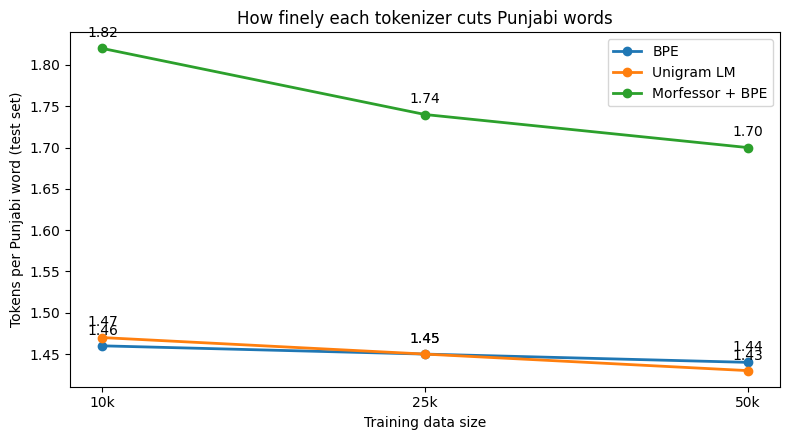

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4.5))
for m in METHODS:
    vals = intrinsic[intrinsic.Method == NAMES[m]].set_index("Train size").loc[SIZES, "Tokens per word"]
    ax.plot(SIZES, vals, marker="o", linewidth=2, label=NAMES[m])
    for x, y in zip(SIZES, vals):
        ax.annotate(f"{y:.2f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_xlabel("Training data size")
ax.set_ylabel("Tokens per Punjabi word (test set)")
ax.set_title("How finely each tokenizer cuts Punjabi words")
ax.legend()
plt.tight_layout()
plt.savefig(f"{PROJECT}/results/figures/04_tokens_per_word.png", dpi=200)
plt.show()

In [ ]:
# Ek taraf STEMS, doosri taraf SUFFIXES.
# Har word ke liye saare possible splits (stem + aakhri 1 se 4 letters) edges bante hain.
import numpy as np

NULL = ""                                             # ∅ = koi suffix nahi (stem khud poora word hai)
MAX_SUF = 4                                           # suffix max 4 characters ka
BAD_START_SPLIT = BAD_START | {"\u0A02", "\u0A70"}    # bindi aur tippi se suffix shuru nahi ho sakta

def candidate_splits(w):
    # Ek word ke saare possible (stem, suffix) splits, Gurmukhi ke niyam maan ke
    out = []
    for k in range(1, MAX_SUF + 1):
        stem, suf = w[:-k], w[-k:]
        if len(stem) < 2 or stem[-1] in BAD_END or suf[0] in BAD_START_SPLIT:
            continue
        out.append((stem, suf))
    return out

def build_graph(word_counts):
    vocab = set(word_counts)
    stem_sufs = {}
    for w in vocab:
        for stem, suf in candidate_splits(w):
            stem_sufs.setdefault(stem, set()).add(suf)
    for stem in stem_sufs:
        if stem in vocab:
            stem_sufs[stem].add(NULL)                 # stem khud bhi ek word hai (jaise ਕਿਤਾਬ)
    # Sirf woh stems rakho jo kam se kam 2 alag suffixes ke saath dikhe
    stem_sufs = {s: f for s, f in stem_sufs.items() if len(f) >= 2}
    stems = sorted(stem_sufs)
    sufs = sorted({f for fs in stem_sufs.values() for f in fs})
    s_id = {s: i for i, s in enumerate(stems)}
    f_id = {f: i for i, f in enumerate(sufs)}
    pairs = [(s_id[s], f_id[f]) for s, fs in stem_sufs.items() for f in fs]
    return {"stems": stems, "sufs": sufs, "s_id": s_id, "f_id": f_id,
            "si": np.array([p[0] for p in pairs]), "fi": np.array([p[1] for p in pairs]),
            "counts": word_counts}

graphs = {}
for k in SIZES:
    g = build_graph(gurmukhi_word_counts(train[k]["pa"]))
    graphs[k] = g
    print(f"{k}: {len(g['counts']):,} words -> {len(g['stems']):,} stems, "
          f"{len(g['sufs']):,} suffixes, {len(g['si']):,} edges")

10k: 16,660 words -> 7,807 stems, 6,918 suffixes, 32,904 edges
25k: 27,430 words -> 12,567 stems, 10,339 suffixes, 56,650 edges
50k: 39,635 words -> 17,912 stems, 13,711 suffixes, 84,388 edges


In [ ]:
# HITS: do scores jo ek doosre ko baar baar update karte hain
#   suffix ka score (authority) = us se jude saare stems ke scores ka jod
#   stem ka score (hub)         = us se jude saare suffixes ke scores ka jod
# SEEDS: Punjabi grammar ke jaane-maane suffixes. alpha > 0 par har round mein
# inhe thoda extra score milta hai. Yahi title ka "Linguistic" hissa hai.
SEEDS = ["ਾ", "ੇ", "ੀ", "ੀਆਂ", "ਾਂ", "ਿਆਂ", "ਿਆ",       # gender, number, plural
         "ਦਾ", "ਦੀ", "ਦੇ", "ਦੀਆਂ",                      # ਕਰਦਾ, ਕਰਦੀ (verb -ing)
         "ਣਾ", "ਨਾ", "ਣ", "ਕੇ"]                           # ਜਾਣਾ, ਕਰਨਾ, ਜਾਣ, ਕਰਕੇ
ALPHA = 0.2

def hits(g, alpha=0.0, seeds=(), iters=100):
    si, fi = g["si"], g["fi"]
    nS, nF = len(g["stems"]), len(g["sufs"])
    seed = np.zeros(nF)
    for s in seeds:
        if s in g["f_id"]:
            seed[g["f_id"][s]] = 1
    if seed.sum():
        seed /= seed.sum()
    h = np.ones(nS) / nS
    for _ in range(iters):
        a = np.bincount(fi, weights=h[si], minlength=nF); a /= a.sum()
        if alpha:
            a = (1 - alpha) * a + alpha * seed
        h = np.bincount(si, weights=a[fi], minlength=nS); h /= h.sum()
    return h, a

for k in SIZES:
    g = graphs[k]
    g["hub0"], g["auth0"] = hits(g)                              # bina seeds
    g["hub"], g["auth"] = hits(g, alpha=ALPHA, seeds=SEEDS)       # seeds ke saath
print("Seeds found in the 50k graph:", sum(s in graphs["50k"]["f_id"] for s in SEEDS), "of", len(SEEDS))

# Check: hamara HITS (bina seeds) networkx library ke HITS jaisa hi result dena chahiye
import networkx as nx
g = graphs["10k"]
G = nx.DiGraph()
G.add_edges_from((("S", g["stems"][a]), ("F", g["sufs"][b])) for a, b in zip(g["si"], g["fi"]))
_, nx_auth = nx.hits(G, max_iter=1000, tol=1e-10)
ours = {g["sufs"][i] for i in np.argsort(-g["auth0"])[:10]}
theirs = {n[1] for n, _ in sorted(((n, v) for n, v in nx_auth.items() if n[0] == "F"), key=lambda x: -x[1])[:10]}
print("Top 10 suffixes same as networkx:", ours == theirs)

Seeds found in the 50k graph: 15 of 15
Top 10 suffixes same as networkx: True


In [ ]:
def ranking(g, scores):
    return [g["sufs"][i] for i in np.argsort(-scores) if g["sufs"][i] != NULL]

g = graphs["50k"]
degree = np.bincount(g["fi"], minlength=len(g["sufs"])).astype(float)   # kitne stems se juda
rank_deg, rank_h0, rank_h = ranking(g, degree), ranking(g, g["auth0"]), ranking(g, g["auth"])

top = pd.DataFrame({
    "By degree (simple count)": ["-" + s for s in rank_deg[:15]],
    "HITS, no seeds": ["-" + s for s in rank_h0[:15]],
    "HITS, with seeds": ["-" + s for s in rank_h[:15]],
}, index=range(1, 16))
top.to_csv(f"{PROJECT}/results/suffix_ranking_top15.csv")
top

,By degree (simple count),"HITS, no seeds","HITS, with seeds"
1,-ੀ,-ੀ,-ੀ
2,-ਾ,-ਾਂ,-ਾ
3,-ਾਂ,-ਾ,-ਾਂ
4,-ੇ,-ੇ,-ੇ
5,-ਰ,-ੀਆਂ,-ੀਆਂ
6,-ਨ,-ਆਂ,-ਿਆ
7,-ਆਂ,-ਨ,-ਣ
8,-ੀਆਂ,-ਰ,-ਿਆਂ
9,-ਲ,-ਿਆ,-ਦਾ
10,-ਸ,-ਣ,-ਦੇ


In [ ]:
check = [("ਾਂ", "real suffix"), ("ੀਆਂ", "real suffix"), ("ਿਆਂ", "real suffix"), ("ਦਾ", "real suffix"),
         ("ਣ", "real suffix"), ("ਰ", "final letter"), ("ਲ", "final letter"), ("ਸ", "final letter"),
         ("ਤ", "final letter"), ("ਕ", "final letter")]
def rank_of(order, s):
    return order.index(s) + 1 if s in order else None
ranks = pd.DataFrame([{"Suffix": "-" + s, "Type": t,
                       "Rank by degree": rank_of(rank_deg, s),
                       "Rank HITS (no seeds)": rank_of(rank_h0, s),
                       "Rank HITS (with seeds)": rank_of(rank_h, s)} for s, t in check])
ranks.to_csv(f"{PROJECT}/results/suffix_rank_check.csv", index=False)
ranks

,Suffix,Type,Rank by degree,Rank HITS (no seeds),Rank HITS (with seeds)
0,-ਾਂ,real suffix,3,2,3
1,-ੀਆਂ,real suffix,8,5,5
2,-ਿਆਂ,real suffix,16,15,8
3,-ਦਾ,real suffix,25,17,9
4,-ਣ,real suffix,12,10,7
5,-ਰ,final letter,5,8,18
6,-ਲ,final letter,9,12,22
7,-ਸ,final letter,10,11,20
8,-ਤ,final letter,13,20,24
9,-ਕ,final letter,11,13,21


In [ ]:
# Graph ke scores se word todne ka niyam:
#   1. Jo word training mein F ya zyada baar aaya, use poora rakho
#   2. Baaki words mein sirf EK cut: stem + suffix, jahan suffix top-K list mein ho
#      aur stem graph mein ho. Kai options hon toh score = suffix score x stem score sabse zyada wala.
import math

def make_segmenter(g, K, F, seeded=True):
    auth, hub = (g["auth"], g["hub"]) if seeded else (g["auth0"], g["hub0"])
    allowed = set(ranking(g, auth)[:K])
    counts, cache = g["counts"], {}
    def segment(w):
        if w not in cache:
            best, best_score = [w], 0.0
            if counts.get(w, 0) < F:
                for stem, suf in candidate_splits(w):
                    if suf in allowed and stem in g["s_id"]:
                        sc = auth[g["f_id"][suf]] * hub[g["s_id"][stem]]
                        if sc > best_score:
                            best, best_score = [stem, suf], sc
            cache[w] = best
        return cache[w]
    return segment

def bits_per_word(segment, train_counts, valid_counts):
    # Validation text ko likhne mein kitne "bits" lagenge (kam = behtar):
    #   training mein dekha piece: uski frequency se cost
    #   naya piece: "naya hai" ki cost + use letter-by-letter likhne ki cost
    pieces = Counter()
    for w, c in train_counts.items():
        p = segment(w)
        pieces[p[0]] += c
        for q in p[1:]:
            pieces["+" + q] += c                  # "+" = suffix piece (alag word se farak)
    N = sum(pieces.values())
    p_new = max(sum(v == 1 for v in pieces.values()), 1) / N
    chars = Counter()
    for w, c in train_counts.items():
        for ch in w + "$":
            chars[ch] += c
    total_ch = sum(chars.values()) + len(chars) + 1
    def spell(piece):
        return sum(-math.log2((chars.get(ch, 0) + 1) / total_ch) for ch in piece + "$")
    bits = words = 0
    for w, c in valid_counts.items():
        p = segment(w)
        cost = 0.0
        for key in [p[0]] + ["+" + q for q in p[1:]]:
            if key in pieces:
                cost += -math.log2((1 - p_new) * pieces[key] / N)
            else:
                cost += -math.log2(p_new) + spell(key.lstrip("+"))
        bits += c * cost
        words += c
    return bits / words

def split_share(segment, counts):
    # Training ke kitne % words toote
    total = sum(counts.values())
    return 100 * sum(c for w, c in counts.items() if len(segment(w)) > 1) / total

valid_counts = gurmukhi_word_counts(valid["pa"])
print("Ready. Validation words:", sum(valid_counts.values()))

Ready. Validation words: 23932


In [ ]:
K_GRID = [15, 30, 60, 120]                     # kitne top suffixes allowed
F_GRID = [2, 5, 10, 25, 100, 10**9]            # 10**9 = frequency ki koi limit nahi
VARIANTS = {"graph": True, "graph0": False}    # graph = seeds ke saath, graph0 = bina seeds

t0 = time.time()
tuning, best = [], {}
for v, seeded in VARIANTS.items():
    for k in SIZES:
        g = graphs[k]
        for K in K_GRID:
            for F in F_GRID:
                seg = make_segmenter(g, K, F, seeded)
                tuning.append({"Variant": v, "Train size": k, "K": K, "F": F,
                               "Bits per word": round(bits_per_word(seg, g["counts"], valid_counts), 3),
                               "Words split (%)": round(split_share(seg, g["counts"]), 1)})
tuning = pd.DataFrame(tuning)
tuning.to_csv(f"{PROJECT}/results/graph_tuning.csv", index=False)

rows = []
for v, seeded in VARIANTS.items():
    for k in SIZES:
        t = tuning[(tuning.Variant == v) & (tuning["Train size"] == k)]
        b = t.loc[t["Bits per word"].idxmin()]
        best[(v, k)] = (int(b.K), int(b.F))
        nosplit = bits_per_word(lambda w: [w], graphs[k]["counts"], valid_counts)
        rows.append({"Variant": "with seeds" if seeded else "no seeds", "Train size": k,
                     "Best K": int(b.K), "Best F": "no limit" if b.F >= 10**9 else int(b.F),
                     "Words split (%)": b["Words split (%)"],
                     "Bits per word": b["Bits per word"], "Bits, no splitting": round(nosplit, 3)})
best_table = pd.DataFrame(rows)
best_table.to_csv(f"{PROJECT}/results/graph_best_settings.csv", index=False)
print(f"{time.time()-t0:.0f} sec")
best_table

30 sec


,Variant,Train size,Best K,Best F,Words split (%),Bits per word,"Bits, no splitting"
0,with seeds,10k,15,2,1.4,13.611,13.616
1,with seeds,25k,15,2,0.8,13.062,13.052
2,with seeds,50k,15,2,0.6,12.771,12.779
3,no seeds,10k,15,2,1.7,13.686,13.616
4,no seeds,25k,15,2,1.1,13.114,13.052
5,no seeds,50k,30,2,1.0,12.797,12.779


In [ ]:
# Bilkul Morfessor + BPE jaisa, bas deewar kahan lage yeh graph decide karta hai
graph_seg = {"graph": {}, "graph0": {}}
t0 = time.time()
for v, seeded in VARIANTS.items():
    for k in SIZES:
        K, F = best[(v, k)]
        seg = make_segmenter(graphs[k], K, F, seeded)
        graph_seg[v][k] = seg
        for name, d in [(f"train_{k}", train[k]), ("valid", valid), ("test", test)]:
            out = d.copy()
            out["pa"] = out["pa"].map(lambda s: pretokenize(s, seg))
            out.to_parquet(f"{PRETOK}/{v}_{k}_{name}.parquet", index=False)
        pre_train = pd.read_parquet(f"{PRETOK}/{v}_{k}_train_{k}.parquet")
        sp[(v, k)] = train_sp(pre_train["pa"].tolist(), f"pa_{v}_{k}", "bpe",
                              pretokenization_delimiter=DELIM, user_defined_symbols=[DELIM])
        print(f"{v}_{k} ready (K={K}, F={F})")
print(f"{time.time()-t0:.0f} sec")

graph_10k ready (K=15, F=2)
graph_25k ready (K=15, F=2)
graph_50k ready (K=15, F=2)
graph0_10k ready (K=15, F=2)
graph0_25k ready (K=15, F=2)
graph0_50k ready (K=30, F=2)
25 sec


In [ ]:
SEGMENTERS = {"morfessor": morf, "graph": graph_seg["graph"], "graph0": graph_seg["graph0"]}
METHODS = ["bpe", "unigram", "morfessor", "graph0", "graph"]
NAMES = {"bpe": "BPE", "unigram": "Unigram LM", "morfessor": "Morfessor + BPE",
         "graph0": "Graph + BPE (no seeds)", "graph": "Graph + BPE (ours)"}

def encode(method, k, sentence):
    if method in SEGMENTERS:
        sentence = pretokenize(sentence, SEGMENTERS[method][k])
    return [p for p in sp[(method, k)].encode(sentence, out_type=str) if p != DELIM]

rows = []
for k in SIZES:
    for m in METHODS:
        pieces = [p for s in test["pa"] for p in encode(m, k, s)]
        ids = [sp[(m, k)].piece_to_id(p) for p in pieces]
        rows.append({
            "Train size": k, "Method": NAMES[m],
            "Tokens per word": round(len(pieces) / test_words, 2),
            "Tokens per sentence": round(len(pieces) / len(test), 1),
            "Unknown tokens (%)": round(100 * sum(i == 1 for i in ids) / len(ids), 3),
            "Vocab pieces used": len(set(ids)),
        })
intrinsic = pd.DataFrame(rows)
intrinsic.to_csv(f"{PROJECT}/results/tokenizer_intrinsic.csv", index=False)
intrinsic

,Train size,Method,Tokens per word,Tokens per sentence,Unknown tokens (%),Vocab pieces used
0,10k,BPE,1.46,37.3,0.080,4343
1,10k,Unigram LM,1.47,37.6,0.079,3864
2,10k,Morfessor + BPE,1.82,46.7,0.064,3344
3,10k,Graph + BPE (no seeds),1.47,37.6,0.079,4323
4,10k,Graph + BPE (ours),1.46,37.5,0.079,4336
5,25k,BPE,1.45,37.0,0.075,4413
6,25k,Unigram LM,1.45,37.1,0.075,3980
7,25k,Morfessor + BPE,1.74,44.5,0.062,3728
8,25k,Graph + BPE (no seeds),1.46,37.3,0.074,4403
9,25k,Graph + BPE (ours),1.45,37.2,0.074,4404


In [ ]:
rows = []
for s in examples + [test["pa"].iloc[0]]:
    for m in METHODS:
        toks = encode(m, "10k", s)
        rows.append({"Sentence": s[:25], "Method": NAMES[m], "Count": len(toks), "Pieces": " | ".join(toks)})
ex = pd.DataFrame(rows)
ex.to_csv(f"{PROJECT}/results/tokenizer_examples.csv", index=False)
ex

,Sentence,Method,Count,Pieces
0,ਉਹ ਸਕੂਲ ਵਿੱਚ ਪੜ੍ਹਦੀ ਹੈ।,BPE,7,▁ਉਹ | ▁ਸਕੂਲ | ▁ਵਿੱਚ | ▁ਪੜ੍ਹ | ਦੀ | ▁ਹੈ | ।
1,ਉਹ ਸਕੂਲ ਵਿੱਚ ਪੜ੍ਹਦੀ ਹੈ।,Unigram LM,7,▁ਉਹ | ▁ਸਕੂਲ | ▁ਵਿੱਚ | ▁ਪੜ੍ਹ | ਦੀ | ▁ਹੈ | ।
2,ਉਹ ਸਕੂਲ ਵਿੱਚ ਪੜ੍ਹਦੀ ਹੈ।,Morfessor + BPE,7,▁ਉਹ | ▁ਸਕੂਲ | ▁ਵਿੱਚ | ▁ਪੜ੍ਹ | ਦੀ | ▁ਹੈ | ।
3,ਉਹ ਸਕੂਲ ਵਿੱਚ ਪੜ੍ਹਦੀ ਹੈ।,Graph + BPE (no seeds),8,▁ਉਹ | ▁ਸਕੂਲ | ▁ਵਿੱਚ | ▁ਪੜ੍ਹ | ਦ | ੀ | ▁ਹੈ | ।
4,ਉਹ ਸਕੂਲ ਵਿੱਚ ਪੜ੍ਹਦੀ ਹੈ।,Graph + BPE (ours),7,▁ਉਹ | ▁ਸਕੂਲ | ▁ਵਿੱਚ | ▁ਪੜ੍ਹ | ਦੀ | ▁ਹੈ | ।
5,ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾ,BPE,7,▁ਵਿਦਿਆਰਥੀਆਂ | ▁ਨੇ | ▁ਆਪਣੀਆਂ | ▁ਕਿਤਾਬਾਂ | ▁ਲਿਖ | ੀਆਂ | ।
6,ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾ,Unigram LM,7,▁ਵਿਦਿਆਰਥੀਆਂ | ▁ਨੇ | ▁ਆਪਣੀਆਂ | ▁ਕਿਤਾਬਾਂ | ▁ਲਿਖ | ੀਆਂ | ।
7,ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾ,Morfessor + BPE,12,▁ਵਿਦਿਆ | ਰਥੀ | ਆਂ | ▁ਨੇ | ▁ਆਪ | ਣ | ੀਆਂ | ▁ਕਿਤਾਬ | ਾਂ | ▁ਲਿਖ | ੀਆਂ | ।
8,ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾ,Graph + BPE (no seeds),7,▁ਵਿਦਿਆਰਥੀਆਂ | ▁ਨੇ | ▁ਆਪਣੀਆਂ | ▁ਕਿਤਾਬਾਂ | ▁ਲਿਖ | ੀਆਂ | ।
9,ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾ,Graph + BPE (ours),7,▁ਵਿਦਿਆਰਥੀਆਂ | ▁ਨੇ | ▁ਆਪਣੀਆਂ | ▁ਕਿਤਾਬਾਂ | ▁ਲਿਖ | ੀਆਂ | ।


In [ ]:
# Har us word ko todo jisme top-15 (seed) suffix mile, frequency ki koi limit nahi
v = "graphA"
graph_seg[v] = {}
for k in SIZES:
    seg = make_segmenter(graphs[k], 15, 10**9, seeded=True)
    graph_seg[v][k] = seg
    for name, d in [(f"train_{k}", train[k]), ("valid", valid), ("test", test)]:
        out = d.copy()
        out["pa"] = out["pa"].map(lambda s: pretokenize(s, seg))
        out.to_parquet(f"{PRETOK}/{v}_{k}_{name}.parquet", index=False)
    pre_train = pd.read_parquet(f"{PRETOK}/{v}_{k}_train_{k}.parquet")
    sp[(v, k)] = train_sp(pre_train["pa"].tolist(), f"pa_{v}_{k}", "bpe",
                          pretokenization_delimiter=DELIM, user_defined_symbols=[DELIM])
    print(f"{v}_{k}: words split {split_share(seg, graphs[k]['counts']):.1f}%, "
          f"bits per word {bits_per_word(seg, graphs[k]['counts'], valid_counts):.3f}")

graphA_10k: words split 27.3%, bits per word 14.642
graphA_25k: words split 28.4%, bits per word 14.227
graphA_50k: words split 29.1%, bits per word 13.997


In [ ]:
SEGMENTERS = {"morfessor": morf, "graph": graph_seg["graph"],
              "graph0": graph_seg["graph0"], "graphA": graph_seg["graphA"]}
METHODS = ["bpe", "unigram", "morfessor", "graph0", "graph", "graphA"]
NAMES = {"bpe": "BPE", "unigram": "Unigram LM", "morfessor": "Morfessor + BPE",
         "graph0": "Graph, no seeds", "graph": "Graph, rare words (ours)",
         "graphA": "Graph, all words (ours)"}
rows = []
for k in SIZES:
    for m in METHODS:
        pieces = [p for s in test["pa"] for p in encode(m, k, s)]
        ids = [sp[(m, k)].piece_to_id(p) for p in pieces]
        rows.append({"Train size": k, "Method": NAMES[m],
                     "Tokens per word": round(len(pieces) / test_words, 2),
                     "Tokens per sentence": round(len(pieces) / len(test), 1),
                     "Unknown tokens (%)": round(100 * sum(i == 1 for i in ids) / len(ids), 3),
                     "Vocab pieces used": len(set(ids))})
intrinsic = pd.DataFrame(rows)
intrinsic.to_csv(f"{PROJECT}/results/tokenizer_intrinsic.csv", index=False)
intrinsic.pivot(index="Method", columns="Train size", values="Tokens per sentence")[SIZES].loc[[NAMES[m] for m in METHODS]]

Train size,10k,25k,50k
Method,,,
BPE,37.3,37.0,37.0
Unigram LM,37.6,37.1,36.7
Morfessor + BPE,46.7,44.5,43.5
"Graph, no seeds",37.6,37.3,37.3
"Graph, rare words (ours)",37.5,37.2,37.1
"Graph, all words (ours)",42.7,42.9,42.8


In [ ]:
rows = []
for s in examples[1:] + [test["pa"].iloc[0]]:
    for m in ["bpe", "morfessor", "graph", "graphA"]:
        toks = encode(m, "10k", s)
        rows.append({"Sentence": s[:25], "Method": NAMES[m], "Count": len(toks), "Pieces": " | ".join(toks)})
ex = pd.DataFrame(rows)
ex.to_csv(f"{PROJECT}/results/tokenizer_examples.csv", index=False)
ex

,Sentence,Method,Count,Pieces
0,ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾ,BPE,7,▁ਵਿਦਿਆਰਥੀਆਂ | ▁ਨੇ | ▁ਆਪਣੀਆਂ | ▁ਕਿਤਾਬਾਂ | ▁ਲਿਖ | ੀਆਂ | ।
1,ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾ,Morfessor + BPE,12,▁ਵਿਦਿਆ | ਰਥੀ | ਆਂ | ▁ਨੇ | ▁ਆਪ | ਣ | ੀਆਂ | ▁ਕਿਤਾਬ | ਾਂ | ▁ਲਿਖ | ੀਆਂ | ।
2,ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾ,"Graph, rare words (ours)",7,▁ਵਿਦਿਆਰਥੀਆਂ | ▁ਨੇ | ▁ਆਪਣੀਆਂ | ▁ਕਿਤਾਬਾਂ | ▁ਲਿਖ | ੀਆਂ | ।
3,ਵਿਦਿਆਰਥੀਆਂ ਨੇ ਆਪਣੀਆਂ ਕਿਤਾ,"Graph, all words (ours)",10,▁ਵਿਦਿਆਰਥ | ੀਆਂ | ▁ਨੇ | ▁ਆਪਣ | ੀਆਂ | ▁ਕਿਤਾਬ | ਾਂ | ▁ਲਿਖ | ੀਆਂ | ।
4,“ਹੁਣ ਸਾਡੇ ਕੋਲ 4 ਮਹੀਨਿਆਂ ਦ,BPE,32,"▁“ | ਹੁਣ | ▁ਸਾਡੇ | ▁ਕੋਲ | ▁4 | ▁ਮਹੀਨਿਆਂ | ▁ਦਾ | ▁ਚੂ | ਹੇ | ▁ਹਨ | ▁ਜੋ | ▁ਗੈਰ | - | ਸ਼ੁ | ਗਰ | ▁ਰੋ | ਗੀ | ▁ਹਨ | ▁ਜੋ | ▁ਸ਼ੁ | ਗਰ | ▁ਰੋਗ | ੀਆਂ | ▁ਲਈ | ▁ਵਰਤੇ | ▁ਜਾਂਦੇ | ▁ਹਨ | ”, | ▁ਉਸਨੇ | ▁ਜੋ | ੜਿਆ | ।"
5,“ਹੁਣ ਸਾਡੇ ਕੋਲ 4 ਮਹੀਨਿਆਂ ਦ,Morfessor + BPE,38,"▁“ | ਹੁਣ | ▁ਸਾ | ਡੇ | ▁ਕੋਲ | ▁4 | ▁ਮਹੀ | ਨ | ਿਆਂ | ▁ਦਾ | ▁ਚੂ | ਹੇ | ▁ਹਨ | ▁ਜੋ | ▁ਗੈਰ | - | ਸ਼ੁ | ਗਰ | ▁ਰੋਗ | ੀ | ▁ਹਨ | ▁ਜੋ | ▁ਸ਼ੁ | ਗਰ | ▁ਰੋਗ | ੀਆਂ | ▁ਲਈ | ▁ਵਰਤ | ੇ | ▁ਜਾਂ | ਦੇ | ▁ਹਨ | ”, | ▁ਉਸ | ਨੇ | ▁ਜੋੜ | ਿਆ | ।"
6,“ਹੁਣ ਸਾਡੇ ਕੋਲ 4 ਮਹੀਨਿਆਂ ਦ,"Graph, rare words (ours)",32,"▁“ | ਹੁਣ | ▁ਸਾਡੇ | ▁ਕੋਲ | ▁4 | ▁ਮਹੀਨਿਆਂ | ▁ਦਾ | ▁ਚੂ | ਹੇ | ▁ਹਨ | ▁ਜੋ | ▁ਗੈਰ | - | ਸ਼ੁ | ਗਰ | ▁ਰੋਗ | ੀ | ▁ਹਨ | ▁ਜੋ | ▁ਸ਼ੁ | ਗਰ | ▁ਰੋਗ | ੀਆਂ | ▁ਲਈ | ▁ਵਰਤੇ | ▁ਜਾਂਦੇ | ▁ਹਨ | ”, | ▁ਉਸਨੇ | ▁ਜੋੜ | ਿਆ | ।"
7,“ਹੁਣ ਸਾਡੇ ਕੋਲ 4 ਮਹੀਨਿਆਂ ਦ,"Graph, all words (ours)",40,"▁“ | ਹੁ | ਣ | ▁ਸਾਡ | ੇ | ▁ਕੋਲ | ▁4 | ▁ਮਹੀਨ | ਿਆਂ | ▁ਦਾ | ▁ਚ | ੂਹ | ੇ | ▁ਹਨ | ▁ਜੋ | ▁ਗੈਰ | - | ਸ਼ | ੁ | ਗਰ | ▁ਰੋਗ | ੀ | ▁ਹਨ | ▁ਜੋ | ▁ਸ਼ੁ | ਗਰ | ▁ਰੋਗ | ੀਆਂ | ▁ਲਈ | ▁ਵਰਤ | ੇ | ▁ਜਾਂਦ | ੇ | ▁ਹਨ | ”, | ▁ਉਸਨ | ੇ | ▁ਜੋੜ | ਿਆ | ।"


In [ ]:
# Yeh cells apne aap mein poore hain: Colab restart ke baad
# sirf Cell 2 aur Cell 3 chala ke seedha yahan se shuru kar sakti hai.
import os, math, time, random, warnings
import numpy as np, pandas as pd, torch, torch.nn as nn
import sentencepiece as spm, sacrebleu
warnings.filterwarnings("ignore")

TOK = f"{PROJECT}/tokenizers"
PRETOK = f"{PROJECT}/data/pretok"
MODELS = f"{PROJECT}/models"
OUT = f"{PROJECT}/results/translations"
RESULTS = f"{PROJECT}/results/mt_results.csv"
os.makedirs(MODELS, exist_ok=True)
os.makedirs(OUT, exist_ok=True)
DELIM = "\u241F"
PAD, UNK, BOS, EOS = 0, 1, 2, 3
MAX_LEN = 160
device = "cuda" if torch.cuda.is_available() else "cpu"

def set_seed(s=1):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def load_split(method, k, split):
    # bpe/unigram: asli text. Baaki methods: pehle se pretokenize kiya hua text (Drive se)
    name = f"train_{k}" if split == "train" else split
    if method in ("bpe", "unigram"):
        return pd.read_parquet(f"{PROJECT}/data/splits/{name}.parquet")
    return pd.read_parquet(f"{PRETOK}/{method}_{k}_{name}.parquet")

def load_data(method, k):
    sp_src = spm.SentencePieceProcessor(model_file=f"{TOK}/pa_{method}_{k}.model")
    sp_tgt = spm.SentencePieceProcessor(model_file=f"{TOK}/en_bpe_{k}.model")
    did = sp_src.piece_to_id(DELIM)
    delim_id = did if sp_src.id_to_piece(did) == DELIM else None     # deewar wala token hatana hai
    enc_src = lambda s: [i for i in sp_src.encode(s) if i != delim_id][:MAX_LEN - 1] + [EOS]
    enc_tgt = lambda s: [BOS] + sp_tgt.encode(s)[:MAX_LEN - 2] + [EOS]
    data = {}
    for split in ["train", "valid", "test"]:
        d = load_split(method, k, split)
        data[split] = {"src": [enc_src(s) for s in d["pa"]],
                       "tgt": [enc_tgt(s) for s in d["en"]],
                       "ref": d["en"].tolist()}
    return data, sp_src, sp_tgt

def make_batches(src, tgt, max_tokens=4096):
    # Same length wale sentences ek batch mein (padding kam, training tez)
    idx = sorted(range(len(src)), key=lambda i: (len(src[i]), len(tgt[i])))
    batches, cur, cur_max = [], [], 0
    for i in idx:
        m = max(cur_max, len(src[i]), len(tgt[i]))
        if cur and m * (len(cur) + 1) > max_tokens:
            batches.append(cur)
            cur, m = [], max(len(src[i]), len(tgt[i]))
        cur.append(i)
        cur_max = m
    if cur:
        batches.append(cur)
    random.shuffle(batches)
    return batches

def pad(seqs):
    L = max(len(s) for s in seqs)
    return torch.tensor([s + [PAD] * (L - len(s)) for s in seqs], device=device)

print("Device:", device)

Device: cuda


In [ ]:
class PosEnc(nn.Module):
    # Word ki position ki jaankari (sin/cos waves), kyunki Transformer khud order nahi jaanta
    def __init__(self, d, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d)
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe)
    def forward(self, x):
        return x + self.pe[: x.size(1)]

class NMT(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, d=256, heads=4, layers=3, ff=1024, dropout=0.3):
        super().__init__()
        self.d = d
        self.src_emb = nn.Embedding(src_vocab, d, padding_idx=PAD)
        self.tgt_emb = nn.Embedding(tgt_vocab, d, padding_idx=PAD)
        self.pos = PosEnc(d)
        self.drop = nn.Dropout(dropout)
        self.tf = nn.Transformer(d, heads, layers, layers, ff, dropout, batch_first=True, norm_first=True)
        self.out = nn.Linear(d, tgt_vocab)
        self.out.weight = self.tgt_emb.weight            # weight tying: kam parameters
        for emb in (self.src_emb, self.tgt_emb):         # chhote random numbers se shuru (stable training)
            nn.init.normal_(emb.weight, 0, d ** -0.5)
            nn.init.zeros_(emb.weight[PAD])
    def encode(self, src):
        mask = src == PAD
        x = self.drop(self.pos(self.src_emb(src) * math.sqrt(self.d)))
        return self.tf.encoder(x, src_key_padding_mask=mask), mask
    def decode(self, tgt, memory, src_mask):
        T = tgt.size(1)
        causal = torch.triu(torch.ones(T, T, dtype=torch.bool, device=tgt.device), 1)   # aage ke words mat dekho
        y = self.drop(self.pos(self.tgt_emb(tgt) * math.sqrt(self.d)))
        h = self.tf.decoder(y, memory, tgt_mask=causal, tgt_key_padding_mask=tgt == PAD,
                            memory_key_padding_mask=src_mask)
        return self.out(h)
    def forward(self, src, tgt_in):
        memory, src_mask = self.encode(src)
        return self.decode(tgt_in, memory, src_mask)

m = NMT(8000, 8000)
print(f"Model parameters: {sum(p.numel() for p in m.parameters()) / 1e6:.1f} million")
del m

Model parameters: 9.6 million


In [ ]:
@torch.no_grad()
def greedy_decode(model, srcs, batch_size=100):
    # Har step par sabse probable word (tez, validation ke liye)
    model.eval()
    outs = [None] * len(srcs)
    order = sorted(range(len(srcs)), key=lambda i: len(srcs[i]))
    for b in range(0, len(order), batch_size):
        ids = order[b:b + batch_size]
        src = pad([srcs[i] for i in ids])
        memory, mask = model.encode(src)
        ys = torch.full((len(ids), 1), BOS, device=device)
        done = torch.zeros(len(ids), dtype=torch.bool, device=device)
        for _ in range(min(MAX_LEN, int(src.size(1) * 1.5) + 10)):
            nxt = model.decode(ys, memory, mask)[:, -1].argmax(-1)
            nxt[done] = PAD
            ys = torch.cat([ys, nxt.unsqueeze(1)], 1)
            done |= nxt == EOS
            if done.all():
                break
        for j, i in enumerate(ids):
            seq = ys[j, 1:].tolist()
            seq = seq[: seq.index(EOS)] if EOS in seq else seq
            outs[i] = [t for t in seq if t != PAD]
    return outs

@torch.no_grad()
def beam_decode(model, src_ids, beam=4, alpha=0.6):
    # Beam search: har step par 4 best adhoore translations yaad rakho (final test ke liye)
    model.eval()
    memory, mask = model.encode(pad([src_ids]))
    beams, finished = [([BOS], 0.0)], []
    for _ in range(min(MAX_LEN, int(len(src_ids) * 1.5) + 10)):
        ys = torch.tensor([b[0] for b in beams], device=device)
        logp = torch.log_softmax(model.decode(ys, memory.expand(len(beams), -1, -1),
                                              mask.expand(len(beams), -1))[:, -1].float(), -1)
        top_lp, top_id = logp.topk(beam, -1)
        cands = [(seq + [t], score + lp) for b, (seq, score) in enumerate(beams)
                 for lp, t in zip(top_lp[b].tolist(), top_id[b].tolist())]
        cands.sort(key=lambda c: -c[1])
        beams = []
        for seq, score in cands:
            if seq[-1] == EOS:
                finished.append((seq, score / (((5 + len(seq)) / 6) ** alpha)))   # length penalty
            else:
                beams.append((seq, score))
            if len(beams) == beam:
                break
        if len(finished) >= beam or not beams:
            break
    if not finished:
        finished = [(s, sc / (((5 + len(s)) / 6) ** alpha)) for s, sc in beams]
    best = max(finished, key=lambda f: f[1])[0]
    return [t for t in best[1:] if t not in (EOS, PAD)]

def score(hyp_ids, refs, sp_tgt):
    hyps = [sp_tgt.decode(h) for h in hyp_ids]
    bleu = sacrebleu.corpus_bleu(hyps, [refs]).score
    chrf = sacrebleu.corpus_chrf(hyps, [refs], word_order=2).score      # chrF++
    return hyps, bleu, chrf

In [ ]:
# Ek (method, data size) ke liye model train karo, phir test set par score karo.
# Har kuch epochs par checkpoint Drive par save hota hai, toh Colab band ho jaaye
# toh dobara chalane par wahin se shuru hoga.
EPOCHS = {"10k": 80, "25k": 50, "50k": 35}      # zyada se zyada epochs
EVAL_EVERY = {"10k": 4, "25k": 2, "50k": 1}     # kitne epochs baad validation check
PATIENCE = 4                                    # itni baar sudhar na ho toh ruk jao (early stopping)

def lr_at(step, warmup=1000, peak=5e-4):
    # Learning rate: pehle dheere badhao (warmup), phir dheere ghatao
    step = max(step, 1)
    return peak * min(step / warmup, math.sqrt(warmup / step))

def run_experiment(method, k, quick=False):
    tag = f"{method}_{k}" + ("_quick" if quick else "")
    set_seed(1)
    data, sp_src, sp_tgt = load_data(method, k)
    model = NMT(sp_src.get_piece_size(), sp_tgt.get_piece_size()).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=5e-4, betas=(0.9, 0.98), eps=1e-9)
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))
    loss_fn = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=0.1)
    ckpt, best_path = f"{MODELS}/{tag}.pt", f"{MODELS}/{tag}_best.pt"
    state = {"step": 0, "epoch": 0, "best_chrf": -1.0, "bad": 0, "finished": False, "minutes": 0.0}
    if os.path.exists(ckpt) and not quick:
        c = torch.load(ckpt, map_location=device)
        model.load_state_dict(c["model"]); opt.load_state_dict(c["opt"]); state = c["state"]
        print(f"Resuming {tag} after epoch {state['epoch']}")
    n_epochs = 2 if quick else EPOCHS[k]
    every = 1 if quick else EVAL_EVERY[k]
    tr_src, tr_tgt = data["train"]["src"], data["train"]["tgt"]
    t0 = time.time() - state["minutes"] * 60
    epoch = state["epoch"]
    while not state["finished"] and epoch < n_epochs:
        epoch += 1
        model.train()
        total, ntok = 0.0, 0
        for b in make_batches(tr_src, tr_tgt):
            src, tgt = pad([tr_src[i] for i in b]), pad([tr_tgt[i] for i in b])
            for g in opt.param_groups:
                g["lr"] = lr_at(state["step"] + 1)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
                logits = model(src, tgt[:, :-1])
                loss = loss_fn(logits.reshape(-1, logits.size(-1)).float(), tgt[:, 1:].reshape(-1))
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            state["step"] += 1
            n = (tgt[:, 1:] != PAD).sum().item()
            total += loss.item() * n
            ntok += n
        if epoch % every == 0 or epoch == n_epochs:
            _, bleu, chrf = score(greedy_decode(model, data["valid"]["src"]), data["valid"]["ref"], sp_tgt)
            mins = (time.time() - t0) / 60
            print(f"{tag} epoch {epoch}: train loss {total / ntok:.3f} | valid BLEU {bleu:.2f}, chrF++ {chrf:.2f} | {mins:.1f} min")
            if chrf > state["best_chrf"]:
                state["best_chrf"], state["bad"] = chrf, 0
                torch.save(model.state_dict(), best_path)
            else:
                state["bad"] += 1
            state["epoch"], state["minutes"] = epoch, mins
            state["finished"] = state["bad"] >= PATIENCE or epoch == n_epochs
            if not quick:
                torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "state": state}, ckpt)
            if state["bad"] >= PATIENCE:
                print("Early stopping: validation score sudhar nahi raha")

    # Test set par best model se beam search translation
    model.load_state_dict(torch.load(best_path, map_location=device))
    test_src = data["test"]["src"][:100] if quick else data["test"]["src"]
    refs = data["test"]["ref"][:len(test_src)]
    hyps, bleu, chrf = score([beam_decode(model, s) for s in test_src], refs, sp_tgt)
    print(f"TEST {tag}: BLEU {bleu:.2f}, chrF++ {chrf:.2f}")
    if quick:
        return
    pa = pd.read_parquet(f"{PROJECT}/data/splits/test.parquet")["pa"].tolist()[:len(refs)]
    pd.DataFrame({"pa": pa, "reference": refs, "translation": hyps}).to_csv(f"{OUT}/{tag}.csv", index=False)
    row = {"Method": method, "Train size": k, "Test BLEU": round(bleu, 2), "Test chrF++": round(chrf, 2),
           "Best valid chrF++": round(state["best_chrf"], 2), "Epochs": state["epoch"],
           "Train minutes": round(state["minutes"], 1),
           "Avg source tokens": round(np.mean([len(s) for s in data["test"]["src"]]), 1)}
    res = pd.read_csv(RESULTS) if os.path.exists(RESULTS) else pd.DataFrame(columns=list(row))
    res = res[~((res.Method == method) & (res["Train size"] == k))]
    pd.concat([res, pd.DataFrame([row])], ignore_index=True).to_csv(RESULTS, index=False)
    if os.path.exists(ckpt):
        os.remove(ckpt)                     # resume wali file ki ab zarurat nahi (best model rakha hai)
    print("Saved to", RESULTS)

In [ ]:
# Sab kaam karta hai ya nahi, aur ek epoch kitna time leta hai
run_experiment("bpe", "10k", quick=True)

bpe_10k_quick epoch 1: train loss 8.984 | valid BLEU 0.00, chrF++ 3.72 | 0.3 min
bpe_10k_quick epoch 2: train loss 7.927 | valid BLEU 0.00, chrF++ 3.72 | 0.6 min
TEST bpe_10k_quick: BLEU 0.00, chrF++ 2.82


In [ ]:
# Ek data size ke saare methods train karo. Jo pehle ho chuka hai, woh skip hoga.
def run_all(size):
    methods = ["bpe", "unigram", "morfessor", "graph", "graphA"] + (["graph0"] if size == "10k" else [])
    for m in methods:
        done = set()
        if os.path.exists(RESULTS):
            r = pd.read_csv(RESULTS)
            done = set(zip(r.Method, r["Train size"]))
        if (m, size) in done:
            print("Already done:", m, size)
            continue
        run_experiment(m, size)
    return pd.read_csv(RESULTS)

run_all("10k")

Already done: bpe 10k
Already done: unigram 10k
Already done: morfessor 10k
Already done: graph 10k
Already done: graphA 10k
Already done: graph0 10k


,Method,Train size,Test BLEU,Test chrF++,Best valid chrF++,Epochs,Train minutes,Avg source tokens
0,bpe,10k,1.16,18.19,18.96,80,10.3,38.3
1,unigram,10k,1.36,18.36,18.75,76,10.1,38.6
2,morfessor,10k,1.09,17.75,18.10,80,12.9,48.1
3,graph,10k,1.38,18.23,18.65,80,10.3,38.5
4,graphA,10k,1.41,17.88,18.49,80,11.8,43.7
5,graph0,10k,1.17,18.16,18.87,80,10.4,38.6
6,bpe,25k,2.27,20.05,20.39,50,13.8,38.0
7,unigram,25k,2.41,20.22,20.65,50,14.0,38.1
8,morfessor,25k,1.93,19.47,20.10,50,16.3,45.7
9,graph,25k,2.32,20.04,20.32,50,13.8,38.2


In [ ]:
# Cell 47: Kaun sach mein BPE se alag hai? (paired bootstrap significance test)
# Test set ko 2000 baar random dobara banao, aur dekho ki do methods ka farak
# har baar same direction mein rehta hai ya nahi. "95% range" mein 0 aa gaya,
# toh farak kismat ho sakta hai (Significant? = no)
res = pd.read_csv(RESULTS)
NAMES = {"bpe": "BPE", "unigram": "Unigram LM", "morfessor": "Morfessor + BPE",
         "graph0": "Graph, no seeds", "graph": "Graph, rare words (ours)", "graphA": "Graph, all words (ours)"}
ORDER = ["bpe", "unigram", "morfessor", "graph0", "graph", "graphA"]

def sent_chrf(method, k):
    # Har test sentence ka alag chrF++ score
    t = pd.read_csv(f"{OUT}/{method}_{k}.csv").fillna("")
    return np.array([sacrebleu.sentence_chrf(str(h), [str(r)], word_order=2).score
                     for h, r in zip(t.translation, t.reference)])

def bootstrap(a, b, n=2000, seed=1):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(a), (n, len(a)))
    diff = a[idx].mean(1) - b[idx].mean(1)
    return (a - b).mean(), np.percentile(diff, 2.5), np.percentile(diff, 97.5)

def compare(k):
    base = sent_chrf("bpe", k)
    rows = []
    for m in ORDER:
        r = res[(res.Method == m) & (res["Train size"] == k)]
        if r.empty:
            continue
        r = r.iloc[0]
        row = {"Method": NAMES[m], "Test BLEU": r["Test BLEU"], "Test chrF++": r["Test chrF++"],
               "Avg source tokens": r["Avg source tokens"]}
        if m != "bpe":
            d, lo, hi = bootstrap(sent_chrf(m, k), base)
            row.update({"Diff vs BPE": round(d, 2), "95% range": f"{lo:+.2f} to {hi:+.2f}",
                        "Significant?": "yes" if (lo > 0 or hi < 0) else "no"})
        rows.append(row)
    out = pd.DataFrame(rows).fillna("")
    out.to_csv(f"{PROJECT}/results/mt_comparison_{k}.csv", index=False)
    return out

comp = compare("10k")
comp

,Method,Test BLEU,Test chrF++,Avg source tokens,Diff vs BPE,95% range,Significant?
0,BPE,1.16,18.19,38.3,,,
1,Unigram LM,1.36,18.36,38.6,0.22,-0.09 to +0.53,no
2,Morfessor + BPE,1.09,17.75,48.1,-0.53,-0.85 to -0.20,yes
3,"Graph, no seeds",1.17,18.16,38.6,-0.06,-0.35 to +0.23,no
4,"Graph, rare words (ours)",1.38,18.23,38.5,0.02,-0.27 to +0.31,no
5,"Graph, all words (ours)",1.41,17.88,43.7,-0.37,-0.69 to -0.03,yes


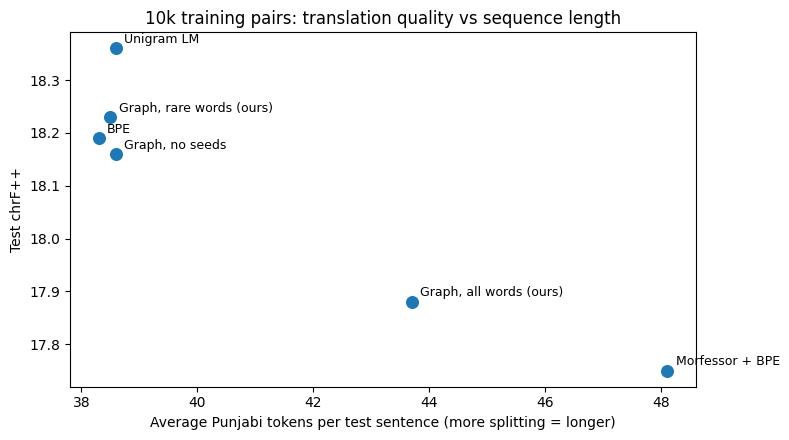

In [ ]:

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(comp["Avg source tokens"], comp["Test chrF++"], s=70)
for _, r in comp.iterrows():
    ax.annotate(r.Method, (r["Avg source tokens"], r["Test chrF++"]), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set_xlabel("Average Punjabi tokens per test sentence (more splitting = longer)")
ax.set_ylabel("Test chrF++")
ax.set_title("10k training pairs: translation quality vs sequence length")
plt.tight_layout()
plt.savefig(f"{PROJECT}/results/figures/05_chrf_vs_length_10k.png", dpi=200)
plt.show()

In [ ]:

t = {m: pd.read_csv(f"{OUT}/{m}_10k.csv").fillna("") for m in ["bpe", "morfessor", "graph", "graphA"]}
short = [i for i in range(len(t["bpe"])) if 6 <= len(str(t["bpe"].reference[i]).split()) <= 12][:4]
for i in short:
    print("PUNJABI  :", t["bpe"].pa[i])
    print("REFERENCE:", t["bpe"].reference[i])
    for m in t:
        print(f"{NAMES[m]:26s}:", t[m].translation[i])
    print("-" * 90)

PUNJABI  : ਉਸਨੇ ਕਿਹਾ, ਉਸਨੇ ਇੱਕ ਵਾਈ-ਫਾਈ ਡੋਰ ਬੈੱਲ ਬਣਾਈ ਹੈ।
REFERENCE: He built a WiFi door bell, he said.
BPE                       : He said that he will be a form.
Morfessor + BPE           : He said her parents had an old-watching at her himself.
Graph, rare words (ours)  : He said he would be a man.
Graph, all words (ours)   : He said that I am an unfair that I am as well as well as well as a ""mts.
------------------------------------------------------------------------------------------
PUNJABI  : 2017 ਦੇ ਅਖੀਰ ਵਿੱਚ, ਸਿਮਿਨੌਫ ਸ਼ਾਪਿੰਗ ਟੈਲੀਵਿਜ਼ਨ ਚੈਨਲ QVC 'ਤੇ ਨਜ਼ਰ ਆਏ।
REFERENCE: In late 2017, Siminoff appeared on shopping television channel QVC.
BPE                       : Mumbai: Mumbai Indians has released a multi-EECTA project in Mumbai.
Morfessor + BPE           : Startart and the most important important role in the next next few minutes.
Graph, rare words (ours)  : India has released a new new-USUSUSEECTCTC.
Graph, all words (ours)   : India is scheduled for online States.
-------

In [ ]:

run_all("25k")

Already done: bpe 25k
Already done: unigram 25k
Already done: morfessor 25k
Already done: graph 25k
Already done: graphA 25k


,Method,Train size,Test BLEU,Test chrF++,Best valid chrF++,Epochs,Train minutes,Avg source tokens
0,bpe,10k,1.16,18.19,18.96,80,10.3,38.3
1,unigram,10k,1.36,18.36,18.75,76,10.1,38.6
2,morfessor,10k,1.09,17.75,18.10,80,12.9,48.1
3,graph,10k,1.38,18.23,18.65,80,10.3,38.5
4,graphA,10k,1.41,17.88,18.49,80,11.8,43.7
5,graph0,10k,1.17,18.16,18.87,80,10.4,38.6
6,bpe,25k,2.27,20.05,20.39,50,13.8,38.0
7,unigram,25k,2.41,20.22,20.65,50,14.0,38.1
8,morfessor,25k,1.93,19.47,20.10,50,16.3,45.7
9,graph,25k,2.32,20.04,20.32,50,13.8,38.2


In [ ]:
# ---------------- Cell 51: 50k ke saare methods train karo ----------------
# T4 par lagbhag 1.5 se 2 ghante. Beech mein band ho jaaye toh upar wale
# cells chala ke yeh dobara chalao, jo ho chuka hai woh skip hoga.
run_all("50k")

Already done: bpe 50k
Already done: unigram 50k
Already done: morfessor 50k
Already done: graph 50k
Already done: graphA 50k


,Method,Train size,Test BLEU,Test chrF++,Best valid chrF++,Epochs,Train minutes,Avg source tokens
0,bpe,10k,1.16,18.19,18.96,80,10.3,38.3
1,unigram,10k,1.36,18.36,18.75,76,10.1,38.6
2,morfessor,10k,1.09,17.75,18.10,80,12.9,48.1
3,graph,10k,1.38,18.23,18.65,80,10.3,38.5
4,graphA,10k,1.41,17.88,18.49,80,11.8,43.7
5,graph0,10k,1.17,18.16,18.87,80,10.4,38.6
6,bpe,25k,2.27,20.05,20.39,50,13.8,38.0
7,unigram,25k,2.41,20.22,20.65,50,14.0,38.1
8,morfessor,25k,1.93,19.47,20.10,50,16.3,45.7
9,graph,25k,2.32,20.04,20.32,50,13.8,38.2


In [ ]:
# ---------------- Cell 52: 25k aur 50k ka significance test ----------------
# Cell 47 wala compare() use karta hai. res ko dobara load karna zaroori hai.
res = pd.read_csv(RESULTS)
comp25 = compare("25k")
display(comp25)
comp50 = compare("50k")
display(comp50)

,Method,Test BLEU,Test chrF++,Avg source tokens,Diff vs BPE,95% range,Significant?
0,BPE,2.27,20.05,38.0,,,
1,Unigram LM,2.41,20.22,38.1,0.23,-0.12 to +0.57,no
2,Morfessor + BPE,1.93,19.47,45.7,-0.55,-0.91 to -0.19,yes
3,"Graph, rare words (ours)",2.32,20.04,38.2,0.17,-0.17 to +0.49,no
4,"Graph, all words (ours)",2.34,20.65,43.9,0.66,+0.30 to +1.02,yes


,Method,Test BLEU,Test chrF++,Avg source tokens,Diff vs BPE,95% range,Significant?
0,BPE,3.08,21.48,38.0,,,
1,Unigram LM,3.10,21.33,37.7,-0.17,-0.51 to +0.19,no
2,Morfessor + BPE,2.86,21.37,44.3,-0.15,-0.50 to +0.21,no
3,"Graph, rare words (ours)",3.05,21.75,38.1,0.25,-0.07 to +0.58,no
4,"Graph, all words (ours)",3.02,21.63,43.8,0.1,-0.24 to +0.44,no


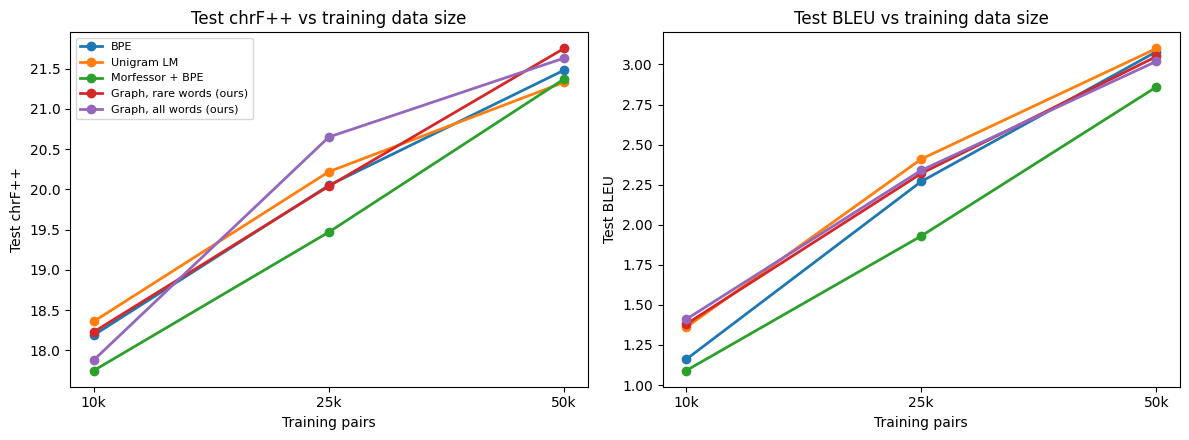

In [ ]:
# ---------------- Cell 53: Score vs data size (report ka main graph) ----------------
res = pd.read_csv(RESULTS)
SIZES = ["10k", "25k", "50k"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric in zip(axes, ["Test chrF++", "Test BLEU"]):
    for m in ORDER:
        r = res[res.Method == m].set_index("Train size")
        xs = [s for s in SIZES if s in r.index]
        if len(xs) < 2:            # graph0 sirf 10k par hai, line nahi banegi
            continue
        ax.plot(xs, r.loc[xs, metric], marker="o", linewidth=2, label=NAMES[m])
    ax.set_xlabel("Training pairs")
    ax.set_ylabel(metric)
    ax.set_title(f"{metric} vs training data size")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{PROJECT}/results/figures/06_scores_vs_size.png", dpi=200)
plt.show()

In [ ]:
# ---------------- Cell 54: Final results table (report ke liye) ----------------
table = res.pivot_table(index="Method", columns="Train size", values=["Test BLEU", "Test chrF++"])
table = table.reindex([m for m in ORDER if m in table.index]).rename(index=NAMES)
table.to_csv(f"{PROJECT}/results/mt_final_table.csv")
display(table)

Test BLEU             Test chrF++              
Train size                     10k   25k   50k         10k    25k    50k
Method                                                                  
BPE                           1.16  2.27  3.08       18.19  20.05  21.48
Unigram LM                    1.36  2.41  3.10       18.36  20.22  21.33
Morfessor + BPE               1.09  1.93  2.86       17.75  19.47  21.37
Graph, no seeds               1.17   NaN   NaN       18.16    NaN    NaN
Graph, rare words (ours)      1.38  2.32  3.05       18.23  20.04  21.75
Graph, all words (ours)       1.41  2.34  3.02       17.88  20.65  21.63

In [ ]:
# ---------------- Cell 55: Teeno sizes ka significance ek jagah ----------------
sig = []
for k in SIZES:
    p = f"{PROJECT}/results/mt_comparison_{k}.csv"
    if os.path.exists(p):
        d = pd.read_csv(p).fillna("")
        d.insert(0, "Train size", k)
        sig.append(d)
sig = pd.concat(sig, ignore_index=True)
sig.to_csv(f"{PROJECT}/results/mt_significance_all.csv", index=False)
sig

,Train size,Method,Test BLEU,Test chrF++,Avg source tokens,Diff vs BPE,95% range,Significant?
0,10k,BPE,1.16,18.19,38.3,,,
1,10k,Unigram LM,1.36,18.36,38.6,0.22,-0.09 to +0.53,no
2,10k,Morfessor + BPE,1.09,17.75,48.1,-0.53,-0.85 to -0.20,yes
3,10k,"Graph, no seeds",1.17,18.16,38.6,-0.06,-0.35 to +0.23,no
4,10k,"Graph, rare words (ours)",1.38,18.23,38.5,0.02,-0.27 to +0.31,no
5,10k,"Graph, all words (ours)",1.41,17.88,43.7,-0.37,-0.69 to -0.03,yes
6,25k,BPE,2.27,20.05,38.0,,,
7,25k,Unigram LM,2.41,20.22,38.1,0.23,-0.12 to +0.57,no
8,25k,Morfessor + BPE,1.93,19.47,45.7,-0.55,-0.91 to -0.19,yes
9,25k,"Graph, rare words (ours)",2.32,20.04,38.2,0.17,-0.17 to +0.49,no
